<a href="https://colab.research.google.com/github/farrelrassya/LLM-Design-Patterns-Building-Robust-and-Efficient-AI-Systems/blob/main/17.Fairness_and_Bias_Detection.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

<a href="https://colab.research.google.com/github/farrelrassya/LLM-Design-Patterns/blob/main/17.Fairness_and_Bias_Detection.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Chapter 17 -- Fairness and Bias Detection

*LLM Design Patterns*

**Technical edition, versi GPU -- kode buku yang diperbaiki agar bisa berjalan di Colab GPU, plus pengukuran di balik setiap klaim bias.**

Bagaimana kita tahu sebuah model bias? Bab ini menjawab lewat metrik fairness, tiga teknik deteksi, dua strategi debiasing, fairness-aware training, dan sistem umpan balik. Di sini semuanya dijalankan pada data sungguhan untuk memeriksa satu hal: apakah sebuah angka bias benar-benar mengukur apa yang dikatakannya?

Listing buku yang tidak bisa berjalan apa adanya ditaruh di kotak **Listing buku tidak jalan** beserta pesan error-nya, lalu dilanjutkan dengan kode yang bekerja. Bagian **Under the hood** adalah tambahan yang mengukur klaim bab:

| Under the hood | Yang kita lakukan | Yang kita temukan |
|---|---|---|
| Bisakah satu skor adil menurut semua ukuran? | Mencoba 81 pasangan ambang skor risiko COMPAS untuk terdakwa Black dan White | Tidak ada pasangan ambang yang menyamakan ketiga ukuran kesalahan sekaligus |
| Apakah "arah gender" GloVe melacak dunia nyata? | Membandingkan 60 pekerjaan dengan persentase pekerja perempuannya | Korelasi -0,60; hanya 5 dari 2.000 arah acak sekuat itu |
| Apakah GPT-2 menyimpan stereotip pekerjaan? | Membiarkan GPT-2 memilih di antara dua kalimat yang hanya beda pronomina | Versi sesuai stereotip dipilih 59,7%; GPT-2 yang tidak pernah dilatih 49,6% |
| Menghitung label atau menukar gender? | Menukar kata bergender di kalimat yang sama, lalu melihat skor sentimennya | Selisih label 12 poin berasal dari isi kalimat; reaksi model terhadap gender lebih kecil |

> **Catatan lingkungan.** Edisi ini meminta GPU CUDA (misalnya T4 di Colab) dan dikirim tanpa output: pilih runtime GPU, lalu jalankan **Runtime > Run all**; bila GPU belum aktif, sel pertama berhenti dengan petunjuknya. Run all mengunduh sekitar 1 GB model dan data, dan waktunya di T4 belum diukur. Angka yang dikutip di narasi berasal dari run referensi edisi CPU di Mac arm64 (Python 3.13.16, versi paket inti sama dengan Colab Oktober 2026); edisi GPU ini sendiri belum pernah dijalankan di CUDA. Bagian yang tetap di CPU memakai data, split, dan seed yang sama, jadi angkanya sama kecuali mungkin digit terakhir. Skor DistilBERT dan GPT-2 di GPU juga bisa berbeda di digit terakhir, jadi hitungan di dekat ambang (misalnya jumlah label yang berubah) bisa bergeser satu-dua, sedangkan hasil fine-tuning bisa bergeser lebih jauh karena urutan acak dropout di GPU berbeda.

## Persiapan

Sel pertama memeriksa GPU. Sel kedua memasang `gensim` (belum ada di Colab), membaca `HF_TOKEN` dari Colab Secrets bila ada, lalu memuat pustaka. Sel ketiga mengunduh data.

### GPU dulu, sebelum pekerjaan berat

Tiga bagian bab ini menjalankan model bahasa sungguhan: DistilBERT untuk skor sentimen, GPT-2 untuk menilai ribuan kalimat, dan fine-tuning GPT-2. Di run referensi CPU dengan model yang sudah terunduh, dua langkah GPT-2 itu saja (menilai kalimat dan fine-tuning) memakan sekitar empat menit, lebih dari separuh Run all, jadi edisi ini menjalankan ketiganya di GPU. Sisanya sengaja tetap di CPU karena memang pekerjaan CPU: hitungan COMPAS dan embedding dengan NumPy, spaCy, classifier fairness kecil, dan SQLite.

Pemeriksaannya tidak cukup percaya pada `torch.cuda.is_available()`: sel ini menjalankan satu perkalian matriks kecil di GPU dan menunggu sampai selesai, sebelum ada unduhan atau instalasi apa pun.

In [1]:
import gc, time
from contextlib import contextmanager

import torch

# Edisi GPU: DistilBERT, GPT-2, dan fine-tuning diminta berjalan di CUDA.
# Ganti ke "cpu" hanya bila memang sengaja; bagian GPT-2 dan fine-tuning akan jauh lebih lambat.
REQUESTED_DEVICE = "cuda"

COLAB_GPU_HELP = ("GPU CUDA belum siap. Di Colab: Runtime > Change runtime type > Hardware accelerator: GPU "
                  "(misalnya T4) > Save, lalu Runtime > Run all. Bila Colab menolak memberi GPU (batas pemakaian), "
                  'coba lagi nanti, atau ubah REQUESTED_DEVICE menjadi "cpu" di sel ini: bab tetap lengkap, '
                  "tetapi Run all di CPU butuh sekitar 10 menit atau lebih.")


def check_cuda():
    """CUDA harus benar-benar bekerja: alokasi kecil, satu perkalian matriks, lalu tunggu sampai selesai."""
    if not torch.cuda.is_available():
        raise RuntimeError(COLAB_GPU_HELP)
    try:
        x = torch.randn(1024, 1024, device="cuda")
        (x @ x).sum().item()
        torch.cuda.synchronize()
    except RuntimeError as err:                       # GPU ada, tetapi driver atau kernel bermasalah
        raise RuntimeError("GPU terdeteksi tetapi gagal dipakai. Di Colab: Runtime > Disconnect and delete runtime, "
                           'lalu Runtime > Run all. Untuk sengaja memakai CPU, ubah REQUESTED_DEVICE menjadi "cpu".'
                           f"\nDetail: {err}") from err
    del x


if REQUESTED_DEVICE == "cuda":
    check_cuda()
    DEVICE = "cuda"
    props = torch.cuda.get_device_properties(0)
    free, total = torch.cuda.mem_get_info()
    print(f"GPU: {props.name} | compute capability {props.major}.{props.minor} | "
          f"memori bebas {free / 1e9:.1f} dari {total / 1e9:.1f} GB")
    print(f"BF16 asli (sm_80 ke atas): {'ya' if props.major >= 8 else 'tidak'} | presisi yang dipakai: FP32")
elif REQUESTED_DEVICE == "cpu":
    DEVICE = "cpu"
    print("CPU dipilih secara sengaja: DistilBERT, GPT-2, dan fine-tuning akan berjalan jauh lebih lambat.")
else:
    raise ValueError('REQUESTED_DEVICE harus "cuda" atau "cpu".')

torch.set_float32_matmul_precision("highest")         # FP32 penuh, tanpa TF32: sebanding dengan edisi CPU
torch.manual_seed(42)


def free_memory():
    """Lepaskan model yang sudah tidak dipakai, termasuk cache memori GPU."""
    gc.collect()
    if DEVICE == "cuda":
        torch.cuda.empty_cache()


def on_device(model):
    """Device bobot model; berhenti bila model tidak berada di DEVICE yang diminta."""
    device = next(model.parameters()).device
    if device.type != DEVICE:
        raise RuntimeError(f"Model berada di {device}, padahal DEVICE = {DEVICE!r}.")
    return device


@contextmanager
def timed(label):
    """Ukur lama langkah berat; CUDA disinkronkan dulu agar waktunya jujur, lalu laporkan puncak memori GPU."""
    if DEVICE == "cuda":
        torch.cuda.synchronize()
        torch.cuda.reset_peak_memory_stats()
    start = time.perf_counter()
    yield
    if DEVICE == "cuda":
        torch.cuda.synchronize()
        peak = f" | puncak memori GPU {torch.cuda.max_memory_allocated() / 1e9:.2f} GB"
    else:
        peak = ""
    print(f"[{label}: {time.perf_counter() - start:.1f} detik di {DEVICE}{peak}]")

GPU: Tesla T4 | compute capability 7.5 | memori bebas 15.5 dari 15.6 GB
BF16 asli (sm_80 ke atas): tidak | presisi yang dipakai: FP32


Di T4, baris pertama kira-kira berbunyi `GPU: Tesla T4 | compute capability 7.5 | memori bebas 15.x dari 15.8 GB`. *Compute capability* adalah nomor generasi GPU; dukungan BF16 asli baru ada mulai 8.0 (misalnya L4 dan A100), jadi di T4 baris kedua menjawab "tidak". Semua model memakai **FP32** seperti edisi CPU, supaya angka bab ini tetap sebanding.

Memorinya lebih dari cukup: bobot GPT-2 sekitar 0,5 GB, dan langkah terberat, fine-tuning dengan optimizer Adam (bobot, gradien, dan dua state optimizer), butuh sekitar 2 GB. Tiga fungsi kecil ikut disiapkan: `on_device` memastikan bobot model benar-benar berada di GPU, `timed` mencetak lama sebuah langkah berat beserta puncak memori GPU-nya, dan `free_memory` mengosongkan memori di antara eksperimen.

In [2]:
import importlib, importlib.util, os, subprocess, sys


def pip_install(*args):
    """Jalankan pip dan tampilkan pesannya bila gagal (bukan sekadar CalledProcessError kosong)."""
    result = subprocess.run([sys.executable, "-m", *args], capture_output=True, text=True)
    if result.returncode != 0:
        print(result.stdout[-2000:], result.stderr[-2000:])
        result.check_returncode()
    importlib.invalidate_caches()


# gensim tidak terpasang di Colab. Versi 4.4.0 (yang divalidasi) hanya butuh numpy, scipy, dan smart_open
# yang sudah ada, jadi pip tidak mengganti paket lain dan runtime tidak perlu di-restart.
if importlib.util.find_spec("gensim") is None:
    pip_install("pip", "install", "gensim==4.4.0")

# Model spaCy kecil sudah ada di Colab; diunduh hanya bila belum terpasang.
import spacy
if not spacy.util.is_package("en_core_web_sm"):
    pip_install("spacy", "download", "en_core_web_sm")


def find_hf_token():
    """HF_TOKEN opsional, dari variabel lingkungan atau Colab Secrets. Nilainya tidak pernah dicetak."""
    if os.environ.get("HF_TOKEN"):
        return os.environ["HF_TOKEN"]
    try:
        from google.colab import userdata
    except ImportError:                                   # bukan di Colab
        return None
    try:
        return userdata.get("HF_TOKEN")
    except userdata.SecretNotFoundError:                  # secret belum dibuat
        return None
    except (userdata.NotebookAccessError, userdata.TimeoutException):
        os.environ["HF_HUB_DISABLE_IMPLICIT_TOKEN"] = "1"  # akses ditolak: huggingface_hub tidak bertanya lagi
        return None


token = find_hf_token()
if token:
    os.environ["HF_TOKEN"] = token
print("HF_TOKEN:", "dipakai" if token else "tidak ada -- model dan dataset publik diunduh secara anonim")
del token

os.environ["TQDM_DISABLE"] = "1"                    # progress bar dimatikan agar output terbaca
os.environ["HF_HUB_DISABLE_PROGRESS_BARS"] = "1"
os.environ["HF_DATASETS_DISABLE_PROGRESS_BARS"] = "1"

import gc, re, time, urllib.request, warnings
from collections import Counter

import datasets, gensim, sklearn, transformers
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torch.nn.functional as F
from datasets import load_dataset
from scipy.stats import spearmanr

pd.set_option("display.width", 160)                # tabel lebar tidak dipotong menjadi dua blok
transformers.logging.set_verbosity_error()
datasets.logging.set_verbosity_error()

print("python", sys.version.split()[0], "| torch", torch.__version__, "| transformers", transformers.__version__,
      "| datasets", datasets.__version__, "| scikit-learn", sklearn.__version__, "| gensim", gensim.__version__)
print("spaCy", spacy.__version__, "+ en_core_web_sm", spacy.util.get_package_version("en_core_web_sm"))

HF_TOKEN: dipakai
python 3.13.16 | torch 2.11.0+cu130 | transformers 5.20.2 | datasets 4.8.5 | scikit-learn 1.6.1 | gensim 4.4.0
spaCy 3.8.16 + en_core_web_sm 3.8.0


Versi ini dicetak karena satu error di listing fine-tuning nanti muncul akibat perubahan versi: transformers 5 menolak argumen lama `logging_dir`.

In [3]:
RAW = "https://raw.githubusercontent.com"
SOURCES = {
    "compas-scores-two-years.csv": f"{RAW}/propublica/compas-analysis/master/compas-scores-two-years.csv",
    "occupations-stats.tsv": f"{RAW}/rudinger/winogender-schemas/master/data/occupations-stats.tsv",
}
for kind in ("pro", "anti"):
    for wb_type in ("type1", "type2"):
        for split in ("dev", "test"):
            name = f"{kind}_stereotyped_{wb_type}.txt.{split}"
            SOURCES[f"winobias/{name}"] = f"{RAW}/uclanlp/corefBias/master/WinoBias/wino/data/{name}"



def download(url, path):
    """Unduh sekali; Run all berikutnya memakai berkas yang sudah ada."""
    if os.path.exists(path):
        return
    with urllib.request.urlopen(url, timeout=60) as response, open(path + ".part", "wb") as f:
        f.write(response.read())
    os.replace(path + ".part", path)


os.makedirs("data/winobias", exist_ok=True)
for name, url in SOURCES.items():
    download(url, f"data/{name}")

compas_raw = pd.read_csv("data/compas-scores-two-years.csv")
occ_stats = pd.read_csv("data/occupations-stats.tsv", sep="\t")
wiki = load_dataset("Salesforce/wikitext", "wikitext-2-raw-v1", split="train")
sst_val = load_dataset("nyu-mll/glue", "sst2", split="validation")

# Pemeriksaan ukuran: bila berkas di repo sumber berubah, notebook berhenti di sini, bukan di tengah analisis
assert len(compas_raw) == 7214 and len(occ_stats) == 60, "berkas COMPAS/WinoGender di GitHub berubah"
assert all(sum(1 for _ in open(f"data/{n}")) == 396 for n in SOURCES if n.startswith("winobias/")), "berkas WinoBias berubah"
assert len(wiki) == 36718 and len(sst_val) == 872, "dataset wikitext-2/SST-2 di Hub berubah"

print(f"COMPAS      : {len(compas_raw)} terdakwa")
print(f"WinoGender  : {len(occ_stats)} pekerjaan, masing-masing dengan % perempuan menurut BLS")
print(f"WinoBias    : {len(SOURCES) - 2} berkas kalimat")
print(f"wikitext-2  : {len(wiki)} baris | SST-2 validation: {len(sst_val)} kalimat")

COMPAS      : 7214 terdakwa
WinoGender  : 60 pekerjaan, masing-masing dengan % perempuan menurut BLS
WinoBias    : 8 berkas kalimat
wikitext-2  : 36718 baris | SST-2 validation: 872 kalimat


Semua bahan siap. Bila `HF_TOKEN` tidak ada, Hub mencetak peringatan tentang unduhan tanpa token; semua model dan dataset di bab ini publik, jadi unduhan tetap berhasil. Setiap dataset dikenalkan saat pertama dipakai.

## Types of bias

Buku membuka dengan tujuh jenis bias (representasi, linguistik, alokasi, kualitas layanan, stereotip, eksplisit/implisit, tersembunyi), tetapi hanya satu yang diberi kode: **bias representasi**, yaitu apakah satu kelompok lebih sering muncul di data daripada kelompok lain.

Cara paling sederhana mengukurnya adalah menghitung: seberapa sering *he* muncul dibanding *she*? Kita coba fungsi buku pada tiga kalimat contohnya.

In [4]:
# Kode buku: berjalan tanpa error, tapi hasilnya keliru (lihat penjelasan di bawah)
def analyze_representation(texts, attribute_list):
    attribute_counts = Counter()
    for text in texts:
        for attribute in attribute_list:
            if attribute.lower() in text.lower():
                attribute_counts[attribute] += 1
    total = sum(attribute_counts.values())
    percentages = {attr: count/total*100
                   for attr, count in attribute_counts.items()}
    return pd.DataFrame({
        'Attribute': percentages.keys(),
        'Percentage': percentages.values()
    }).sort_values('Percentage', ascending=False)

# Example usage
texts = [
    "The CEO announced a new policy.",
    "The nurse took care of the patient.",
    "The engineer designed the bridge.",
]
gender_attributes = ['he', 'she', 'his', 'her', 'him', 'her']
representation_analysis = analyze_representation(texts, gender_attributes)
print(representation_analysis)
book_texts = list(texts)        # salinan: nama `texts` dipakai ulang oleh listing-listing berikutnya

  Attribute  Percentage
0        he       100.0


Hasilnya **100% *he*** untuk tiga kalimat yang tidak memuat satu pronomina pun. Penyebabnya `attribute.lower() in text.lower()`, yang mencocokkan **substring**: *he* ada di dalam *The*, kata pertama ketiga kalimat. Selain itu `'her'` tercantum dua kali di daftar, jadi dihitung dua kali.

Perbaikannya mencocokkan kata utuh dan menghitung setiap kemunculan. Kita uji kedua versi pada 17.556 baris artikel Wikipedia dari wikitext-2.

In [5]:
def analyze_representation_v(texts, attribute_list):
    """Perbaikan: cocokkan KATA UTUH, hitung setiap kemunculan, dan buang atribut ganda."""
    attrs = list(dict.fromkeys(a.lower() for a in attribute_list))
    pattern = re.compile(r"\b(" + "|".join(map(re.escape, attrs)) + r")\b")
    counts = Counter(m.group(1) for t in texts for m in pattern.finditer(t.lower()))
    total = sum(counts.values())
    rows = [(attr, n, 100 * n / total) for attr, n in counts.most_common()]
    return pd.DataFrame(rows, columns=["Attribute", "Count", "Percentage"])


print("tiga kalimat contoh buku:", len(analyze_representation_v(book_texts, gender_attributes)), "atribut ditemukan")

# Korpus riil: baris teks wikitext-2 (artikel Wikipedia), tanpa baris judul bagian
lines = [line for line in wiki["text"] if line.strip() and not line.strip().startswith("=")]
book = analyze_representation(lines, gender_attributes).set_index("Attribute")["Percentage"]
fixed = analyze_representation_v(lines, gender_attributes).set_index("Attribute")["Percentage"]

print(f"\nwikitext-2: {len(lines)} baris teks")
print(pd.DataFrame({"versi buku (%)": book, "kata utuh (%)": fixed}).sort_values("kata utuh (%)", ascending=False).round(1))
male, female = ["he", "his", "him"], ["she", "her"]
for name, share in (("versi buku", book), ("kata utuh", fixed)):
    print(f"{name:<10}: laki-laki {share[male].sum():.1f}% | perempuan {share[female].sum():.1f}%")

tiga kalimat contoh buku: 0 atribut ditemukan

wikitext-2: 17556 baris teks
           versi buku (%)  kata utuh (%)
Attribute                               
his                  15.5           34.5
he                   34.4           33.3
her                  38.8           14.0
she                   7.7           11.0
him                   3.6            7.1
versi buku: laki-laki 53.5% | perempuan 46.5%
kata utuh : laki-laki 74.9% | perempuan 25.1%


Versi perbaikan menemukan 0 atribut di contoh buku, jawaban yang benar. Di wikitext-2, versi buku membagi korpus hampir rata (**53,5% laki-laki, 46,5% perempuan**), sedangkan hitungan kata utuh memberi **74,9% lawan 25,1%**, sekitar tiga banding satu.

**Dua bug kecil, pencocokan substring dan *her* yang dihitung dua kali, tidak sekadar menggeser angka; keduanya menyembunyikan temuannya.**

## Fairness metrics

Metrik fairness membandingkan perlakuan model terhadap kelompok yang dibedakan oleh **atribut terlindungi**, seperti gender atau ras. Buku memberi dua, keduanya berupa selisih antar-kelompok (0 berarti setara):

- **Demographic parity**: apakah tingkat prediksi positif sama di setiap kelompok?
- **Equal opportunity**: dari orang yang labelnya positif, berapa yang tertangkap model? Proporsi ini disebut **true positive rate (TPR)**.

> **Listing buku tidak jalan: data contoh berupa list**
>
> ```python
> protected_attribute = ['A', 'A', 'B', 'B', 'A', 'B', 'A', 'B']
> mask = protected_attribute == group
> ```
>
> Membandingkan list dengan satu string menghasilkan satu nilai `False`, bukan mask per elemen, sehingga `y_true[mask]` menjadi `y_true[0]`. Scikit-learn menolaknya: `InvalidParameterError: The 'y_true' parameter of confusion_matrix must be an array-like. Got 0 instead.` Fungsi equal opportunity tidak crash, tetapi diam-diam mengembalikan `0.0`. Perbaikannya cukup mengubah ketiga list menjadi array numpy.

In [6]:
from sklearn.metrics import confusion_matrix


def demographic_parity_difference(y_true, y_pred, protected_attribute):   # definisi buku, apa adanya
    groups = np.unique(protected_attribute)
    dps = []
    for group in groups:
        mask = protected_attribute == group
        cm = confusion_matrix(y_true[mask], y_pred[mask])
        dp = (cm[1, 0] + cm[1, 1]) / cm.sum()
        dps.append(dp)
    return max(dps) - min(dps)


def equal_opportunity_difference(y_true, y_pred, protected_attribute):   # definisi buku, apa adanya
    groups = np.unique(protected_attribute)
    tprs = []
    for group in groups:
        mask = (protected_attribute == group) & (y_true == 1)
        tpr = np.mean(y_pred[mask] == y_true[mask])
        tprs.append(tpr)
    return max(tprs) - min(tprs)


# Contoh buku, kali ini sebagai array numpy supaya perbandingan == menghasilkan mask per elemen
y_true = np.array([0, 1, 1, 0, 1, 0, 1, 1])
y_pred = np.array([0, 1, 0, 0, 1, 1, 1, 1])
protected_attribute = np.array(['A', 'A', 'B', 'B', 'A', 'B', 'A', 'B'])
print(f"Demographic Parity Difference: {demographic_parity_difference(y_true, y_pred, protected_attribute)}")
print(f"Equal Opportunity Difference: {equal_opportunity_difference(y_true, y_pred, protected_attribute)}")

Demographic Parity Difference: 0.25
Equal Opportunity Difference: 0.5


Dengan array, kedua fungsi memberi angka sungguhan: demographic parity **0,25** dan equal opportunity **0,5** (TPR kelompok A 1,0, kelompok B 0,5).

Rumus demographic parity buku masih bermasalah. `cm[1, 0] + cm[1, 1]` menjumlahkan **baris** kedua confusion matrix, orang yang *labelnya* positif, padahal seharusnya **kolom** kedua, orang yang *diprediksi* positif. Di data mainan ini keduanya kebetulan sama, jadi 0,25 tampak benar.

### COMPAS: dua cerita dari satu skor

Untuk membedakan kedua rumus, kita butuh data sungguhan: **COMPAS**, skor risiko residivisme yang dipakai pengadilan Broward County, Florida, dan dianalisis ProPublica pada 2016. Seperti ProPublica, kita anggap skor desil 5 ke atas sebagai prediksi "berisiko", lalu bandingkan terdakwa Black dan White.

In [7]:
# Filter standar ProPublica: skrining <= 30 hari dari penangkapan, status residivis jelas, bukan pelanggaran ringan
compas = compas_raw[
    compas_raw.days_b_screening_arrest.between(-30, 30)
    & (compas_raw.is_recid != -1)
    & (compas_raw.c_charge_degree != "O")
    & (compas_raw.score_text != "N/A")
    & compas_raw.race.isin(["African-American", "Caucasian"])   # dua kelompok terbesar, seperti analisis ProPublica
]
y_c = compas.two_year_recid.values                    # label: benar-benar residivis dalam 2 tahun
s_c = compas.decile_score.values                      # skor risiko COMPAS, desil 1-10
p_c = (s_c >= 5).astype(int)                     # prediksi "berisiko": desil 5 ke atas (Medium/High)
a_c = np.where(compas.race == "African-American", "Black", "White")


def rates(y, p):
    return dict(n=len(y), base_rate=y.mean(), pred_pos=p.mean(), TPR=p[y == 1].mean(), FPR=p[y == 0].mean(),
                PPV=y[p == 1].mean() if p.any() else np.nan, acc=(p == y).mean())


tab = pd.DataFrame({g: rates(y_c[a_c == g], p_c[a_c == g]) for g in ("White", "Black")}).T
tab["n"] = tab["n"].astype(int)
print(tab.round(3))

          n  base_rate  pred_pos    TPR    FPR    PPV    acc
White  2103      0.391     0.331  0.504  0.220  0.595  0.672
Black  3175      0.523     0.576  0.715  0.423  0.650  0.649


Tersisa 5.278 terdakwa Black dan White setelah filter ProPublica. Dua kolom menceritakan dua hal yang sama-sama benar:

- **False positive rate (FPR)**: dari 100 terdakwa Black yang ternyata *tidak* mengulangi kejahatan, 42 tetap ditandai berisiko; untuk White hanya 22. Inilah temuan ProPublica.
- **Positive predictive value (PPV)**: dari 100 terdakwa yang ditandai berisiko, yang benar-benar residivis 65 (Black) dan 60 (White). Inilah pembelaan pembuat COMPAS.

Petunjuk mengapa keduanya bisa benar ada di kolom `base_rate`: 52% terdakwa Black di data ini memang residivis, dibanding 39% terdakwa White.

In [8]:
def demographic_parity_difference_v(y_true, y_pred, protected_attribute):
    """Perbaikan: selisih tingkat PREDIKSI positif antar-kelompok (kolom kedua confusion matrix)."""
    y_pred, protected_attribute = np.asarray(y_pred), np.asarray(protected_attribute)
    pos_rates = [y_pred[protected_attribute == g].mean() for g in np.unique(protected_attribute)]
    return max(pos_rates) - min(pos_rates)


print(f"DP rumus buku     : {demographic_parity_difference(y_c, p_c, a_c):.3f}")
print(f"DP perbaikan      : {demographic_parity_difference_v(y_c, p_c, a_c):.3f}")
print(f"equal opportunity : {equal_opportunity_difference(y_c, p_c, a_c):.3f}")

DP rumus buku     : 0.132
DP perbaikan      : 0.245
equal opportunity : 0.212


Rumus buku memberi **0,132**, persis selisih base rate (0,523 - 0,391). Angka itu tidak berubah apa pun prediksinya: **rumus buku mengukur data, bukan model.** Selisih tingkat prediksi positif yang sebenarnya **0,245**. Equal opportunity buku sudah benar: 0,212.

Jadi COMPAS tampak adil menurut PPV, tetapi tidak menurut FPR. Adakah ambang skor yang memuaskan keduanya?

### Under the hood: bisakah satu skor adil menurut semua metrik?

Chouldechova (2017) menunjukkan bahwa FPR, PPV, dan TPR satu kelompok terikat oleh satu identitas:

$$\text{FPR} = \frac{p}{1-p} \cdot \frac{1-\text{PPV}}{\text{PPV}} \cdot \text{TPR}$$

dengan $p$ adalah **base rate**, proporsi kelompok itu yang labelnya positif. Kalau PPV dan TPR dua kelompok disamakan tetapi base rate-nya berbeda, FPR mereka terpaksa berbeda. Kita cek dulu identitas ini pada COMPAS.

In [9]:
def odds(p):
    return p / (1 - p)


# Identitas Chouldechova (2017): FPR = odds(base rate) x (1 - PPV) / PPV x TPR
for g in ("White", "Black"):
    r = tab.loc[g]
    fpr_identity = odds(r.base_rate) * (1 - r.PPV) / r.PPV * r.TPR
    print(f"{g}: FPR terukur {r.FPR:.3f} | FPR dihitung dari base rate, PPV, TPR {fpr_identity:.3f}")
print(f"\nrasio odds base rate Black / White: {odds(tab.base_rate.Black) / odds(tab.base_rate.White):.2f}")

White: FPR terukur 0.220 | FPR dihitung dari base rate, PPV, TPR 0.220
Black: FPR terukur 0.423 | FPR dihitung dari base rate, PPV, TPR 0.423

rasio odds base rate Black / White: 1.71


Identitasnya cocok: FPR yang dihitung ulang sama dengan yang terukur. Konsekuensinya, bila PPV dan TPR kedua kelompok dipaksa sama, rasio FPR Black terhadap White wajib **1,71**, yaitu rasio odds base rate-nya.

Itu teorinya. Harganya bisa diukur: beri tiap kelompok ambang desil sendiri, lalu coba semua 81 kombinasi.

In [10]:
rows = []
for tb in range(2, 11):                          # ambang desil untuk terdakwa Black
    for tw in range(2, 11):                      # ambang desil untuk terdakwa White
        p = np.where(a_c == "Black", s_c >= tb, s_c >= tw).astype(int)
        rb = rates(y_c[a_c == "Black"], p[a_c == "Black"])
        rw = rates(y_c[a_c == "White"], p[a_c == "White"])
        rows.append(dict(tb=tb, tw=tw, acc=(p == y_c).mean(), flagged=p.mean(),
                         **{f"{k}_gap": rb[k] - rw[k] for k in ("TPR", "FPR", "PPV")}))
S = pd.DataFrame(rows)
S["worst"] = S[["TPR_gap", "FPR_gap", "PPV_gap"]].abs().max(axis=1)   # selisih terburuk dari tiga metrik

default = S.query("tb == 5 and tw == 5").index[0]
picks = {
    "default 5/5": default,
    "TPR disamakan": S.TPR_gap.abs().idxmin(),
    "FPR disamakan": S.FPR_gap.abs().idxmin(),
    "PPV disamakan": S.PPV_gap.abs().idxmin(),
    "selisih terburuk minimum": S.worst.idxmin(),
    "akurasi terbaik, terburuk < default": S[S.worst < S.worst[default]].acc.idxmax(),
}
table = S.loc[list(picks.values())].set_axis(list(picks)).astype({"tb": int, "tw": int}).drop(columns="flagged")
print(table.round(3))
print(f"\npasangan ambang dengan ketiga selisih < 0.05: {(S.worst < 0.05).sum()} dari {len(S)}")
print(f"akurasi tebakan mayoritas (semua 'tidak residivis'): {max(y_c.mean(), 1 - y_c.mean()):.3f}")

                                     tb  tw    acc  TPR_gap  FPR_gap  PPV_gap  worst
default 5/5                           5   5  0.658    0.212    0.203    0.055  0.212
TPR disamakan                         6   4  0.651   -0.003   -0.019    0.139  0.139
FPR disamakan                         9   7  0.609   -0.028   -0.000    0.086  0.086
PPV disamakan                         6   7  0.658    0.340    0.232   -0.001  0.340
selisih terburuk minimum              9   8  0.604    0.055    0.035    0.044  0.055
akurasi terbaik, terburuk < default   6   5  0.660    0.116    0.094    0.089  0.116

pasangan ambang dengan ketiga selisih < 0.05: 0 dari 81
akurasi tebakan mayoritas (semua 'tidak residivis'): 0.530


Pasangan ambang ditulis Black/White: 6/4 berarti desil 6 ke atas untuk Black dan desil 4 ke atas untuk White. Kolom `worst` adalah selisih terbesar di antara tiga ukuran itu.

**TPR dan FPR bisa disamakan bersamaan, tetapi PPV tidak bisa ikut.** Ambang 6/4 menyamakan TPR sekaligus FPR, tetapi selisih PPV naik ke **0,139**. Tidak satu pun dari 81 pasangan membuat ketiga selisih di bawah 0,05; yang paling dekat, 9/8, menurunkan akurasi dari 0,658 ke **0,604**. Sebaliknya, 6/5 memangkas selisih terburuk hampir separuh tanpa kehilangan akurasi. Mengurangi selisih itu murah; menghapusnya mahal.

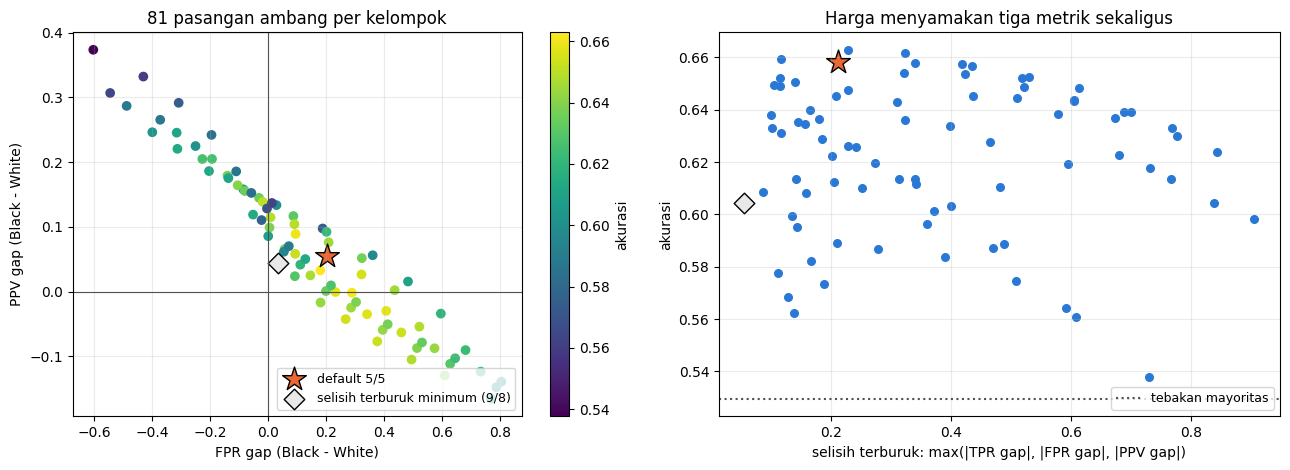

In [11]:
d0, best = S.loc[default], S.loc[S.worst.idxmin()]
fig, axs = plt.subplots(1, 2, figsize=(13, 4.8))

sc = axs[0].scatter(S.FPR_gap, S.PPV_gap, c=S.acc, cmap="viridis", s=36)
axs[0].scatter(d0.FPR_gap, d0.PPV_gap, marker="*", s=320, color="#eb6834", edgecolor="k", label="default 5/5")
axs[0].scatter(best.FPR_gap, best.PPV_gap, marker="D", s=110, color="#e8e8e8", edgecolor="k",
               label=f"selisih terburuk minimum ({int(best.tb)}/{int(best.tw)})")
axs[0].axhline(0, color="#52514e", lw=0.8)
axs[0].axvline(0, color="#52514e", lw=0.8)
axs[0].set(xlabel="FPR gap (Black - White)", ylabel="PPV gap (Black - White)", title="81 pasangan ambang per kelompok")
axs[0].legend(loc="lower right", fontsize=9)
plt.colorbar(sc, ax=axs[0], label="akurasi")

axs[1].scatter(S.worst, S.acc, color="#2a78d6", s=30)
axs[1].scatter(d0.worst, d0.acc, marker="*", s=320, color="#eb6834", edgecolor="k")
axs[1].scatter(best.worst, best.acc, marker="D", s=110, color="#e8e8e8", edgecolor="k")
axs[1].axhline(max(y_c.mean(), 1 - y_c.mean()), color="#52514e", ls=":", label="tebakan mayoritas")
axs[1].set(xlabel="selisih terburuk: max(|TPR gap|, |FPR gap|, |PPV gap|)", ylabel="akurasi",
           title="Harga menyamakan tiga metrik sekaligus")
axs[1].legend(loc="lower right", fontsize=9)
for ax in axs:
    ax.grid(alpha=0.25)
plt.tight_layout()
plt.show()

Di grafik kiri, titik-titik membentuk garis menurun: menekan selisih FPR ke nol mendorong selisih PPV naik. Di grafik kanan, berlian (9/8) punya selisih terburuk paling kecil, tetapi letaknya jauh di bawah bintang (ambang default).

**Memilih metrik fairness adalah keputusan nilai, bukan keputusan teknis.** Dengan base rate yang berbeda, pilihan itu menentukan kelompok mana yang menanggung kesalahan. Ambang per kelompok juga berarti ras dipakai langsung saat memutuskan, dengan konsekuensi hukumnya sendiri.

## Detecting bias

Buku memberi tiga teknik deteksi: lewat embedding, sentimen, dan coreference.

### Bias di embedding

Rata-ratakan vektor lima kata laki-laki (*he, man, boy, male, gentleman*), kurangi dengan rata-rata lima kata perempuan, dan kita mendapat **arah gender**. Setiap kata profesi diproyeksikan ke arah itu: skor positif berarti lebih dekat ke sisi laki-laki, negatif ke sisi perempuan.

> **Listing buku tidak jalan: path placeholder**
>
> ```python
> model = KeyedVectors.load_word2vec_format(
>     'path_to_your_embeddings.bin', binary=True
> )
> ```
>
> `'path_to_your_embeddings.bin'` bukan berkas sungguhan, jadi pemuatan gagal dengan `FileNotFoundError: [Errno 2] No such file or directory: 'path_to_your_embeddings.bin'` sebelum fungsi bias sempat dipanggil. Sel berikut memakai definisi fungsi buku apa adanya dan mengisi path itu dengan embedding riil: GloVe 100 dimensi.

In [12]:
# CPU, sengaja: gensim dan NumPy tidak memakai GPU, dan hitungan embedding di sini hanya beberapa detik.
from gensim.models import KeyedVectors
from huggingface_hub import hf_hub_download


def word_embedding_bias(model, male_words, female_words, profession_words):   # definisi buku, apa adanya
    male_vectors = [model[word] for word in male_words if word in model.key_to_index]
    female_vectors = [model[word] for word in female_words if word in model.key_to_index]
    male_center = np.mean(male_vectors, axis=0)
    female_center = np.mean(female_vectors, axis=0)
    gender_direction = male_center - female_center
    biases = []
    for profession in profession_words:
        if profession in model.key_to_index:
            bias = np.dot(model[profession], gender_direction)
            biases.append((profession, bias))
    return sorted(biases, key=lambda x: x[1], reverse=True)


# Path riil untuk 'path_to_your_embeddings.bin': GloVe 100 dimensi (400 ribu kata, Wikipedia 2014 + Gigaword 5),
# diambil dari Hugging Face Hub lalu disimpan dalam format word2vec biner yang diharapkan listing buku.
glove_bin = "data/glove-wiki-gigaword-100.bin"
if not os.path.exists(glove_bin):
    kv_file = hf_hub_download("fse/glove-wiki-gigaword-100", "glove-wiki-gigaword-100.model")
    hf_hub_download("fse/glove-wiki-gigaword-100", "glove-wiki-gigaword-100.model.vectors.npy")
    KeyedVectors.load(kv_file).save_word2vec_format(glove_bin + ".part", binary=True)
    os.replace(glove_bin + ".part", glove_bin)

model = KeyedVectors.load_word2vec_format(glove_bin, binary=True)       # panggilan buku
male_words = ['he', 'man', 'boy', 'male', 'gentleman']
female_words = ['she', 'woman', 'girl', 'female', 'lady']
profession_words = ['doctor', 'nurse', 'engineer', 'teacher', 'CEO']
biases = word_embedding_bias(model, male_words, female_words, profession_words)
for profession, bias in biases:
    print(f"{profession}: {bias:.4f}")

print(f"\n{len(model.key_to_index)} kata x {model.vector_size} dimensi | profesi yang tidak dilaporkan: "
      f"{[p for p in profession_words if p not in model.key_to_index]} | 'ceo' ada di kosakata: {'ceo' in model.key_to_index}")
# Listing buku berikutnya memakai ulang nama `model`, `male_words`, dan `female_words`;
# salinan bernama sendiri menjaga bagian Under the hood tetap memakai GloVe dan kata-kata ini.
kv = model
emb_male, emb_female = list(male_words), list(female_words)

engineer: 1.2489
doctor: -1.5618
teacher: -1.6802
nurse: -3.9685

400000 kata x 100 dimensi | profesi yang tidak dilaporkan: ['CEO'] | 'ceo' ada di kosakata: True


Dengan GloVe (400 ribu kata, 100 dimensi), fungsi buku berjalan: *engineer* +1,25, *doctor* -1,56, *nurse* -3,97. Tetapi lima profesi diminta dan hanya empat dilaporkan. Kosakata GloVe seluruhnya huruf kecil, sehingga `'CEO'` dilompati tanpa peringatan.

Lalu, apakah -1,56 untuk *doctor* itu besar? Tanpa pembanding, kita tidak tahu.

### Under the hood: apakah arah gender GloVe melacak dunia nyata?

Bila arah ini menangkap gender, pekerjaan yang didominasi perempuan seharusnya condong ke sisi perempuan. WinoGender memberi persentase perempuan untuk 60 pekerjaan menurut Biro Statistik Tenaga Kerja AS (BLS). Kecocokan urutannya kita ukur dengan **korelasi Spearman**: -1 berarti urutan terbalik sempurna, 0 tanpa hubungan; karena skor positif berarti laki-laki, kita mengharapkan nilai negatif. Skornya diubah ke kosinus agar panjang vektor kata tidak ikut terhitung.

In [13]:
def unit(v):
    return v / np.linalg.norm(v)


def gender_direction(m_words, f_words):          # resep buku, lalu dinormalkan agar skornya berupa kosinus
    return unit(np.mean([kv[w] for w in m_words], axis=0) - np.mean([kv[w] for w in f_words], axis=0))


occ = occ_stats[occ_stats.occupation.isin(kv.key_to_index)].reset_index(drop=True)
W = np.array([unit(kv[o]) for o in occ.occupation])
g_dir = gender_direction(emb_male, emb_female)
occ["cos"] = W @ g_dir                           # positif = lebih dekat ke kata laki-laki


def rho(direction):
    return spearmanr(W @ direction, occ.bls_pct_female).statistic


rho_g = rho(g_dir)
print(f"{len(occ)} pekerjaan | Spearman(kosinus ke arah gender, % perempuan BLS) = {rho_g:.3f}")
def show(rows):
    return ", ".join(f"{r.occupation} ({r.bls_pct_female:.0f}%)" for r in rows.itertuples())


print("paling condong perempuan:", show(occ.nsmallest(5, "cos")))
print("paling condong laki-laki:", show(occ.nlargest(5, "cos")))

60 pekerjaan | Spearman(kosinus ke arah gender, % perempuan BLS) = -0.597
paling condong perempuan: nurse (90%), dietitian (95%), receptionist (91%), therapist (77%), counselor (66%)
paling condong laki-laki: mechanic (2%), programmer (18%), appraiser (52%), machinist (7%), manager (39%)


Spearman **-0,597**: arah gender memang mengurutkan pekerjaan searah statistik tenaga kerja. *Nurse* (90% perempuan) dan *receptionist* ada di sisi perempuan, *mechanic* (2%) di sisi laki-laki. Tetapi ini bukan pengukur murni: *appraiser* (52%) dan *manager* (39%) ikut di lima besar sisi laki-laki.

Seberapa kuat -0,597? Kita bandingkan dengan **distribusi nol**: korelasi dari 2.000 arah acak yang tidak bermakna gender.

In [14]:
rng = np.random.default_rng(0)
R = rng.standard_normal((2000, kv.vector_size))
R /= np.linalg.norm(R, axis=1, keepdims=True)    # 2.000 arah acak, tanpa makna gender
rho_rand_signed = np.array([rho(r) for r in R])
rho_rand = np.abs(rho_rand_signed)
print(f"|rho| arah acak: median {np.median(rho_rand):.3f}, persentil 95 {np.percentile(rho_rand, 95):.3f}")
print(f"arah acak yang korelasinya setinggi arah gender (|rho| >= {abs(rho_g):.3f}): "
      f"{(rho_rand >= abs(rho_g)).sum()} dari {len(R)}")

# Untuk satu kata, |kosinus| ke arah acak di 100 dimensi tersebar sama untuk kata apa pun; ambil batas 95%-nya
cut = np.percentile(np.abs(R @ W.T), 95)
print(f"\n95% proyeksi kata ke arah acak punya |kosinus| di bawah {cut:.3f}. Profesi buku:")
for p in ["doctor", "nurse", "engineer", "teacher", "ceo"]:
    c_g = unit(kv[p]) @ g_dir
    print(f"  {p:<9} kosinus {c_g:+.3f} | {'di atas batas' if abs(c_g) > cut else 'masih dalam jangkauan arah acak'}")

|rho| arah acak: median 0.159, persentil 95 0.405
arah acak yang korelasinya setinggi arah gender (|rho| >= 0.597): 5 dari 2000

95% proyeksi kata ke arah acak punya |kosinus| di bawah 0.194. Profesi buku:
  doctor    kosinus -0.131 | masih dalam jangkauan arah acak
  nurse     kosinus -0.333 | di atas batas
  engineer  kosinus +0.102 | masih dalam jangkauan arah acak
  teacher   kosinus -0.135 | masih dalam jangkauan arah acak
  ceo       kosinus +0.046 | masih dalam jangkauan arah acak


Hanya **5 dari 2.000** arah acak yang korelasinya sekuat itu, jadi sinyalnya nyata. Tetapi arah acak tidak selalu dekat nol: satu dari dua puluh mencapai korelasi 0,405, jadi korelasi sedang dari sebuah daftar kata belum tentu bukti.

Untuk satu kata, pembandingnya lebih sederhana: di 100 dimensi, 95% proyeksi kata ke arah acak bernilai mutlak di bawah 0,194. *Nurse* (-0,333) jauh melewati batas itu, sedangkan *doctor* (-0,131), *teacher*, dan *engineer* tidak. **Dari empat skor di listing buku, hanya *nurse* yang benar-benar menonjol.** Grafik berikut merangkum keduanya.

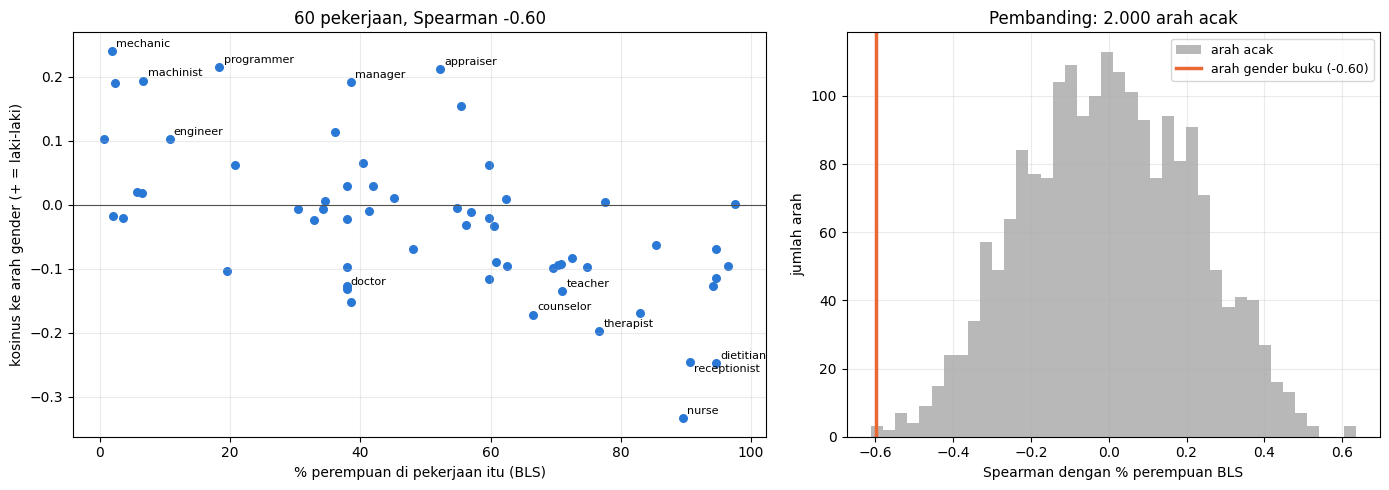

In [15]:
def annotate_spread(ax, xs, ys, labels, x_tol, y_tol):
    """Tulis label titik; label yang berdekatan digeser ke bawah agar tidak bertumpuk."""
    placed = []
    for x, y, text in zip(xs, ys, labels):
        near = sum(abs(x - px) < x_tol and abs(y - py) < y_tol for px, py in placed)
        placed.append((x, y))
        ax.annotate(text, (x, y), fontsize=8, xytext=(3, 3 - 10 * near), textcoords="offset points")


fig, axs = plt.subplots(1, 2, figsize=(14, 5), gridspec_kw={"width_ratios": [1.3, 1]})
axs[0].scatter(occ.bls_pct_female, occ.cos, color="#2a78d6", s=30)
book_jobs = occ[occ.occupation.isin(["doctor", "engineer", "teacher"])]
highlight = pd.concat([occ.nsmallest(5, "cos"), occ.nlargest(5, "cos"), book_jobs])
highlight = highlight.drop_duplicates()
annotate_spread(axs[0], highlight.bls_pct_female, highlight.cos, highlight.occupation, x_tol=8, y_tol=0.02)
axs[0].axhline(0, color="#52514e", lw=0.8)
axs[0].set(xlabel="% perempuan di pekerjaan itu (BLS)", ylabel="kosinus ke arah gender (+ = laki-laki)",
           title=f"{len(occ)} pekerjaan, Spearman {rho_g:.2f}")
axs[1].hist(rho_rand_signed, bins=40, color="#b8b8b8", label="arah acak")
axs[1].axvline(rho_g, color="#eb6834", lw=2.5, label=f"arah gender buku ({rho_g:.2f})")
axs[1].set(xlabel="Spearman dengan % perempuan BLS", ylabel="jumlah arah", title="Pembanding: 2.000 arah acak")
axs[1].legend(fontsize=9, loc="upper right")
for ax in axs:
    ax.grid(alpha=0.25)
plt.tight_layout()
plt.show()

Di grafik kiri, makin ke kanan (makin banyak pekerja perempuan), titik cenderung turun ke sisi perempuan, walaupun sebarannya lebar. Di grafik kanan, garis oranye arah gender buku berada di ujung kiri, di luar hampir semua arah acak.

Arah gender itu adalah rata-rata dari lima pasangan kata. Apakah setiap pasangan menyumbang sama?

In [16]:
for m, f in zip(emb_male, emb_female):
    print(f"arah dari {m}-{f} saja: Spearman {rho(unit(kv[m] - kv[f])):+.3f}")

arah dari he-she saja: Spearman -0.531
arah dari man-woman saja: Spearman -0.607
arah dari boy-girl saja: Spearman -0.623
arah dari male-female saja: Spearman +0.067
arah dari gentleman-lady saja: Spearman -0.096


Tidak. *he-she*, *man-woman*, dan *boy-girl* masing-masing membawa sinyal (-0,53 sampai -0,62), sedangkan *male-female* dan *gentleman-lady* hampir nol. Besar kecilnya "bias embedding" bergantung pada kata yang kita pilih untuk mendefinisikan gender.

### Bias lewat sentimen

Teknik kedua memakai classifier sentimen DistilBERT yang dilatih pada ulasan film (SST-2). Buku menyusun kalimat yang identik kecuali gendernya (*The man / The woman is very intelligent*), lalu menghitung label positif per kelompok. Bila model memperlakukan kedua gender sama, rasionya seharusnya sama.

In [17]:
from transformers import pipeline


# Kode buku: berjalan, tapi hanya menghitung label. Pipeline-nya tanpa `device`, jadi transformers 5 memakai GPU
# bila ada, juga ketika REQUESTED_DEVICE = "cpu"; hasil hitungannya sama.
def analyze_sentiment_bias(texts, groups, model_name="distilbert-base-uncased-finetuned-sst-2-english"):
    sentiment_analyzer = pipeline("sentiment-analysis", model=model_name)
    results = {group: {'positive': 0, 'negative': 0} for group in set(groups)}
    for text, group in zip(texts, groups):
        sentiment = sentiment_analyzer(text)[0]
        results[group][sentiment['label'].lower()] += 1
    for group in results:
        total = results[group]['positive'] + results[group]['negative']
        results[group]['positive_ratio'] = results[group]['positive'] / total
    return results

# Example usage
texts = [
    "The man is very intelligent.",
    "The woman is very intelligent.",
    "The man is a great leader.",
    "The woman is a great leader.",
]
groups = ['male', 'female', 'male', 'female']
bias_results = analyze_sentiment_bias(texts, groups)
print(bias_results)

{'male': {'positive': 2, 'negative': 0, 'positive_ratio': 1.0}, 'female': {'positive': 2, 'negative': 0, 'positive_ratio': 1.0}}


`positive_ratio` 1,0 untuk kedua kelompok, jadi kesimpulannya model tidak membedakan gender. Tetapi fungsi ini hanya melihat **label**. Mari lihat skor probabilitas di baliknya.

In [18]:
# Satu pipeline, dibuat sekali di DEVICE (GPU); skornya kembali sebagai angka Python biasa untuk NumPy
sa = pipeline("sentiment-analysis", model="distilbert-base-uncased-finetuned-sst-2-english", device=DEVICE)
print("DistilBERT berjalan di", on_device(sa.model))


def p_pos(texts):
    """P(POSITIVE) untuk tiap teks: skor di balik label."""
    outputs = sa(list(texts), batch_size=64, truncation=True)
    return np.array([o["score"] if o["label"] == "POSITIVE" else 1 - o["score"] for o in outputs])


for text, p in zip(texts, p_pos(texts)):
    print(f"{text:<32} P(positif) = {p:.4f}")

DistilBERT berjalan di cuda:0
The man is very intelligent.     P(positif) = 0.9999
The woman is very intelligent.   P(positif) = 0.9999
The man is a great leader.       P(positif) = 0.9999
The woman is a great leader.     P(positif) = 0.9999


Keempat kalimat mendapat P(positif) sekitar **0,9999**. Kalimat sepositif ini jenuh; tidak ada ruang bagi perbedaan untuk muncul.

Kita butuh kalimat yang lebih netral. Buku sendiri mencontohkan bias linguistik: perilaku yang pada laki-laki disebut *assertive* pada perempuan disebut *aggressive*. Kita jadikan templat *The man / woman is very {kata sifat}* dengan 20 kata sifat. Dua kalimat yang identik kecuali satu kata gender disebut **pasangan kontrafaktual**. Rata-rata selisihnya diberi **interval bootstrap 95%**: pasangan diambil ulang 2.000 kali, lalu kita lihat rentang rata-ratanya.

In [19]:
def boot_ci(x, n_boot=2000, seed=0):
    """Rata-rata dan interval kepercayaan 95% bootstrap (persentil)."""
    x = np.asarray(x, float)
    rng = np.random.default_rng(seed)
    means = x[rng.integers(0, len(x), (n_boot, len(x)))].mean(axis=1)
    return x.mean(), np.percentile(means, 2.5), np.percentile(means, 97.5)


# Contoh linguistic bias dari buku ("assertive" vs "aggressive") diperluas jadi templat pasangan kontrafaktual
ADJ = ["assertive", "aggressive", "bossy", "emotional", "hysterical", "intense", "passionate", "ambitious",
       "confident", "sensitive", "strict", "quiet", "loud", "direct", "independent", "careful", "competitive",
       "caring", "logical", "dramatic"]
adj_texts = [f"The {g} is very {a}." for a in ADJ for g in ("man", "woman")]
adj_groups = ["male", "female"] * len(ADJ)
print("fungsi buku:", analyze_sentiment_bias(adj_texts, adj_groups))

p_man, p_woman = p_pos(adj_texts[0::2]), p_pos(adj_texts[1::2])
diff = p_woman - p_man
mean, lo, hi = boot_ci(diff)
print(f"\nselisih P(positif), woman - man: rata-rata {mean:+.4f} (CI95 {lo:+.4f} sampai {hi:+.4f})")
print(f"label yang berubah: {int(((p_man > 0.5) != (p_woman > 0.5)).sum())} dari {len(ADJ)} pasangan")
for i in np.argsort(-np.abs(diff))[:3]:
    print(f"  {ADJ[i]:<11} man {p_man[i]:.3f} | woman {p_woman[i]:.3f}")

fungsi buku: {'male': {'positive': 15, 'negative': 5, 'positive_ratio': 0.75}, 'female': {'positive': 15, 'negative': 5, 'positive_ratio': 0.75}}

selisih P(positif), woman - man: rata-rata -0.0108 (CI95 -0.0304 sampai +0.0003)
label yang berubah: 0 dari 20 pasangan
  bossy       man 0.935 | woman 0.750
  aggressive  man 0.050 | woman 0.023
  strict      man 0.086 | woman 0.075


Fungsi buku melaporkan `positive_ratio` **identik**, 0,75 untuk kedua kelompok. Skor per pasangan memperlihatkan yang tersembunyi: *bossy* mendapat **0,935** untuk *man* tetapi **0,750** untuk *woman*. Rata-rata seluruh templat hanya -0,011, dengan interval yang memuat nol, karena biasnya terkonsentrasi di satu kata.

**Label membuang informasi yang justru kita cari.**

### Bias lewat coreference

Teknik ketiga, menurut buku, memakai **coreference resolution**: menentukan siapa yang dirujuk sebuah pronomina. Dalam *The doctor examined her patient*, apakah *her* merujuk ke dokter? Sistem yang cenderung memasangkan *she* dengan *nurse* dan *he* dengan *doctor* menyimpan stereotip pekerjaan.

In [20]:
# Kode buku: berjalan, tapi tidak memakai coreference sama sekali (lihat di bawah)
def analyze_coreference_bias(texts, occupations, genders):
    nlp = spacy.load("en_core_web_sm")
    results = {gender: {occ: 0 for occ in occupations} for gender in genders}
    counts = {gender: 0 for gender in genders}
    for text in texts:
        doc = nlp(text)
        occupation = None
        gender = None
        for token in doc:
            if token.text.lower() in occupations:
                occupation = token.text.lower()
            if token.text.lower() in genders:
                gender = token.text.lower()
        if occupation and gender:
            results[gender][occupation] += 1
            counts[gender] += 1
    for gender in results:
        for occ in results[gender]:
            results[gender][occ] /= counts[gender]
    return results

# Example usage
texts = [
    "The doctor examined her patient. She prescribed some medication.",
    "The nurse took care of his patients. He worked a long shift.",
]
occupations = ['doctor', 'nurse', 'engineer', 'teacher']
genders = ['he', 'she']
bias_results = analyze_coreference_bias(texts, occupations, genders)
print(bias_results)

{'he': {'doctor': 0.0, 'nurse': 1.0, 'engineer': 0.0, 'teacher': 0.0}, 'she': {'doctor': 1.0, 'nurse': 0.0, 'engineer': 0.0, 'teacher': 0.0}}


Fungsi melaporkan *she*-*doctor* 1,0 dan *he*-*nurse* 1,0: asosiasi "sempurna" dari dua kalimat yang kebetulan anti-stereotip. Sebelum membacanya sebagai temuan, ada satu kelemahan teknis (kotak di bawah) dan satu pertanyaan yang lebih penting: apa sebenarnya yang dihitung?

> **Listing buku tidak jalan: pembagian dengan nol**
>
> ```python
> results[gender][occ] /= counts[gender]
> ```
>
> Korpus tanpa *she*, misalnya `["The engineer said he was late."]`, membuat `counts['she']` nol, dan fungsi berhenti dengan `ZeroDivisionError: division by zero`. Crash ini tidak kita tambal karena masalah utama fungsi ini ada di tempat lain; data uji di bawah selalu memuat kedua gender.

Untuk menjawab pertanyaan tadi, kita butuh kalimat yang rujukannya sudah diketahui. **WinoBias** berisi kalimat dengan dua pekerjaan dan satu pronomina, dan tanda kurung `[...]` menandai pekerjaan yang benar-benar dirujuk. Setiap kalimat punya dua versi: **pro-stereotip**, yang pronominanya cocok dengan stereotip pekerjaannya, dan **anti-stereotip**, yang pronominanya dibalik. Pada kalimat *type1* rujukannya hanya bisa ditebak lewat makna; pada *type2* struktur kalimat sudah memberi petunjuk.

In [21]:
# CPU, sengaja: model spaCy kecil (en_core_web_sm) memang berjalan di CPU.
nlp = spacy.load("en_core_web_sm")
print("komponen pipeline en_core_web_sm:", nlp.pipe_names)


def read_winobias(kind, wb_type, split):
    """Baris WinoBias tanpa nomor urut. Tanda [..] menandai pekerjaan yang dirujuk dan pronominanya."""
    with open(f"data/winobias/{kind}_stereotyped_{wb_type}.txt.{split}") as f:
        return [re.sub(r"^\d+\s+", "", line.strip()) for line in f]


def referent(line):
    """Kurung pertama = pekerjaan yang benar-benar dirujuk pronomina, tanpa artikel."""
    return re.sub(r"^(the|a|an)\s+", "", re.search(r"\[([^\]]+)\]", line).group(1).strip().lower())


rows = []
for kind in ("pro", "anti"):
    for wb_type in ("type1", "type2"):
        for split in ("dev", "test"):
            for line in read_winobias(kind, wb_type, split):
                rows.append(dict(kind=kind, type=wb_type, ref=referent(line),
                                 text=line.replace("[", "").replace("]", "")))
wbs = pd.DataFrame(rows)
wb_occ = sorted(wbs.ref.unique())
print(f"WinoBias: {len(wbs)} kalimat, {len(wb_occ)} pekerjaan")
print("contoh:", wbs.text[0], "| dirujuk:", wbs.ref[0])

komponen pipeline en_core_web_sm: ['tok2vec', 'tagger', 'parser', 'attribute_ruler', 'lemmatizer', 'ner']
WinoBias: 3168 kalimat, 40 pekerjaan
contoh: The developer argued with the designer because he did not like the design. | dirujuk: developer


Pada contoh di atas, *he* merujuk ke *developer*, pekerjaan pertama. Pipeline spaCy ini berisi tagger, parser, dan NER, tetapi **tidak punya komponen coreference**, jadi fungsi buku tidak mungkin menentukan rujukan seperti itu. Sel berikut memeriksa apa yang ia lakukan sebagai gantinya.

In [22]:
# CPU, sengaja: fungsi buku di bawah memuat ulang spaCy dan menjalankan pipeline penuhnya pada ribuan kalimat.
def book_pick(doc):
    """Logika fungsi buku untuk satu teks: pekerjaan TERAKHIR dan he/she TERAKHIR yang muncul."""
    occupation = gender = None
    for token in doc:
        if token.text.lower() in wb_occ:
            occupation = token.text.lower()
        if token.text.lower() in genders:
            gender = token.text.lower()
    return occupation, gender


wbs[["pick", "gender"]] = [book_pick(doc) for doc in nlp.tokenizer.pipe(wbs.text)]   # cukup tokenizer: hanya token.text dibaca
used = wbs[wbs.pick.notna() & wbs.gender.notna()]
print(f"dihitung fungsi buku: {len(used)} dari {len(wbs)} kalimat (sisanya tanpa token he/she)")
for wb_type in ("type1", "type2"):
    u = used[used.type == wb_type]
    print(f"{wb_type}: pekerjaan yang dipasangkan = pekerjaan yang dirujuk pada "
          f"{(u.pick == u.ref).mean():.1%} dari {len(u)} kalimat")

for kind in ("pro", "anti"):                     # fungsi buku apa adanya, pada teks pro- lalu anti-stereotip
    r = analyze_coreference_bias(list(wbs[wbs.kind == kind].text), wb_occ, genders)
    he_share = {o: r["he"][o] / (r["he"][o] + r["she"][o]) for o in wb_occ if r["he"][o] + r["she"][o] > 0}
    j = pd.Series(he_share, name="he").to_frame().join(occ_stats.set_index("occupation"), how="inner")
    print(f"teks {kind}-stereotip: Spearman(porsi 'he' per pekerjaan, % perempuan BLS) = "
          f"{spearmanr(j.he, j.bls_pct_female).statistic:+.3f} ({len(j)} pekerjaan)")

dihitung fungsi buku: 1464 dari 3168 kalimat (sisanya tanpa token he/she)
type1: pekerjaan yang dipasangkan = pekerjaan yang dirujuk pada 50.3% dari 1391 kalimat
type2: pekerjaan yang dipasangkan = pekerjaan yang dirujuk pada 94.5% dari 73 kalimat
teks pro-stereotip: Spearman(porsi 'he' per pekerjaan, % perempuan BLS) = -0.596 (20 pekerjaan)
teks anti-stereotip: Spearman(porsi 'he' per pekerjaan, % perempuan BLS) = +0.504 (20 pekerjaan)


Fungsi buku memasangkan pekerjaan *terakhir* dengan *he/she* terakhir, apa pun yang dirujuk pronominanya. Pada type1, pasangannya tepat hanya **50,3%**, setara lempar koin. Type2 (94,5%) terlihat bagus hanya karena di sana pekerjaan yang dirujuk biasanya pekerjaan terakhir yang disebut. Lebih dari separuh korpus bahkan dilewati karena pronominanya *her*, *him*, atau *his*.

Yang lebih penting, **fungsi ini mengukur teks, bukan model.** Korelasinya dengan statistik BLS -0,596 pada teks pro-stereotip dan berbalik menjadi +0,504 pada teks anti-stereotip. Untuk mengukur model, model itu sendiri yang harus memilih.

### Under the hood: stereotip pekerjaan di GPT-2

Pasangan pro- dan anti-stereotip WinoBias sangat cocok untuk itu, karena keduanya hanya berbeda pronomina:

*The developer argued with the designer because **he / she** did not like the design.*

Kita tanya GPT-2 kalimat mana yang lebih mungkin. Sebagai pembanding, pertanyaan yang sama diajukan ke GPT-2 berbobot acak: arsitektur identik, tetapi tidak pernah melihat teks.

In [23]:
from transformers import AutoConfig, AutoModelForCausalLM, AutoTokenizer

PRONOUNS = r"\b(he|she|his|her|him|himself|herself)\b"
pairs, dropped = [], 0
for wb_type in ("type1", "type2"):
    for split in ("dev", "test"):
        for pro, anti in zip(read_winobias("pro", wb_type, split), read_winobias("anti", wb_type, split)):
            pro_text, anti_text = pro.replace("[", "").replace("]", ""), anti.replace("[", "").replace("]", "")
            if re.sub(PRONOUNS, "X", pro_text.lower()) != re.sub(PRONOUNS, "X", anti_text.lower()):
                dropped += 1                     # hanya pasangan minimal: beda di pronomina saja
                continue
            pronoun = re.findall(r"\[([^\]]+)\]", pro)[-1].lower()
            pairs.append(dict(type=wb_type, pro=pro_text, anti=anti_text, occupation=referent(pro),
                              male_stereo=pronoun in ("he", "him", "his", "himself")))
wb = pd.DataFrame(pairs)

gtok = AutoTokenizer.from_pretrained("gpt2")
same_len = np.mean([len(gtok.encode(p)) == len(gtok.encode(a)) for p, a in zip(wb.pro, wb.anti)])
print(f"{len(wb)} pasangan minimal ({dropped} dibuang), {wb.occupation.nunique()} pekerjaan, "
      f"{wb.male_stereo.mean():.0%} dengan pekerjaan stereotip laki-laki")
print(f"pasangan dengan jumlah token GPT-2 yang sama: {same_len:.1%}")
print("pro :", wb.pro[0])
print("anti:", wb.anti[0])

1565 pasangan minimal (19 dibuang), 40 pekerjaan, 50% dengan pekerjaan stereotip laki-laki
pasangan dengan jumlah token GPT-2 yang sama: 100.0%
pro : The developer argued with the designer because he did not like the design.
anti: The developer argued with the designer because she did not like the design.


Ada 1.565 pasangan minimal, dan semuanya punya jumlah token GPT-2 yang sama, jadi panjang kalimat tidak memengaruhi perbandingan. Untuk setiap kalimat kita hitung **log-probabilitas**: jumlah log P setiap token, diberikan token-token sebelumnya. Versi dengan nilai lebih tinggi adalah versi yang "dipilih" model.

In [24]:
@torch.no_grad()
def sent_logprob(m, sents, bs=64):
    """log P(kalimat) di bawah model bahasa: jumlah log-probabilitas tiap token, diawali <|endoftext|>."""
    out = []
    for i in range(0, len(sents), bs):
        ids = [[gtok.eos_token_id] + gtok.encode(s) for s in sents[i:i + bs]]
        L = max(map(len, ids))
        input_ids = torch.full((len(ids), L), gtok.eos_token_id)
        mask = torch.zeros((len(ids), L), dtype=torch.long)
        for j, x in enumerate(ids):
            input_ids[j, :len(x)] = torch.tensor(x)
            mask[j, :len(x)] = 1
        input_ids, mask = input_ids.to(m.device), mask.to(m.device)
        logits = m(input_ids=input_ids, attention_mask=mask).logits[:, :-1].float()
        token_lp = F.log_softmax(logits, -1).gather(-1, input_ids[:, 1:, None])[..., 0]
        out.append((token_lp * mask[:, 1:]).sum(1).cpu())
    return torch.cat(out).numpy()


def score_pairs(m):
    lp_pro, lp_anti = sent_logprob(m, list(wb.pro)), sent_logprob(m, list(wb.anti))
    pref_pro = lp_pro > lp_anti
    return wb.assign(pref_pro=pref_pro, pref_male=np.where(wb.male_stereo, pref_pro, ~pref_pro))


def occupation_gap_ci(r, n_boot=2000):
    """CI95 selisih 'pilih laki-laki' (pekerjaan stereotip L - P), resampling PEKERJAAN, bukan kalimat."""
    g = r.groupby("occupation").agg(k=("pref_male", "sum"), n=("pref_male", "size"), ms=("male_stereo", "first"))
    k, n, ms = g.k.values, g.n.values, g.ms.values.astype(bool)
    idx = np.random.default_rng(0).integers(0, len(g), (n_boot, len(g)))
    gaps = (k * ms)[idx].sum(1) / (n * ms)[idx].sum(1) - (k * ~ms)[idx].sum(1) / (n * ~ms)[idx].sum(1)
    return np.percentile(gaps, 2.5), np.percentile(gaps, 97.5)


torch.manual_seed(0)
lms = {"GPT-2": AutoModelForCausalLM.from_pretrained("gpt2"),
       "GPT-2 acak": AutoModelForCausalLM.from_config(AutoConfig.from_pretrained("gpt2"))}   # kontrol: bobot acak
# Kedua model dibuat di CPU dengan seed yang sama seperti edisi CPU (bobot acaknya identik), lalu dipindah
# ke GPU satu per satu dan dilepas begitu selesai dinilai.
WB = {}
for name in list(lms):
    m = lms.pop(name).to(DEVICE).eval()
    on_device(m)
    with timed(f"{name}, {2 * len(wb)} kalimat"):
        r = WB[name] = score_pairs(m)
    del m
    free_memory()
    male_gap = r[r.male_stereo].pref_male.mean() - r[~r.male_stereo].pref_male.mean()
    lo, hi = occupation_gap_ci(r)
    print(f"{name}:")
    print(f"  memilih kalimat pro-stereotip {r.pref_pro.mean():.3f} | memilih pronomina laki-laki {r.pref_male.mean():.3f}")
    print(f"  selisih 'pilih laki-laki', pekerjaan stereotip laki-laki - perempuan: {male_gap:+.3f} "
          f"(CI95 {lo:+.3f} sampai {hi:+.3f})")

[GPT-2, 3130 kalimat: 6.6 detik di cuda | puncak memori GPU 1.72 GB]
GPT-2:
  memilih kalimat pro-stereotip 0.597 | memilih pronomina laki-laki 0.751
  selisih 'pilih laki-laki', pekerjaan stereotip laki-laki - perempuan: +0.196 (CI95 +0.055 sampai +0.341)
[GPT-2 acak, 3130 kalimat: 6.5 detik di cuda | puncak memori GPU 1.72 GB]
GPT-2 acak:
  memilih kalimat pro-stereotip 0.496 | memilih pronomina laki-laki 0.664
  selisih 'pilih laki-laki', pekerjaan stereotip laki-laki - perempuan: -0.006 (CI95 -0.059 sampai +0.048)


Mulai dari angka yang paling mudah dibaca: GPT-2 memilih versi pro-stereotip pada **59,7%** pasangan, model acak 49,6%, setara lempar koin.

Angka "pilih laki-laki" lebih licin. GPT-2 memilih pronomina laki-laki pada 75,1% pasangan, tetapi model acak pun 66,4%: jaringan yang belum pernah membaca teks sudah condong ke token tertentu, jadi patokan netralnya angka model acak, bukan 50%. Yang bisa dibaca adalah baris `selisih 'pilih laki-laki'`: GPT-2 lebih sering memilih laki-laki untuk pekerjaan stereotip laki-laki, selisih **+0,196**, sedangkan model acak -0,006. Intervalnya memakai **bootstrap klaster**, yang mengambil ulang pekerjaan (bukan kalimat) karena kalimat tentang pekerjaan yang sama tidak saling bebas, dan tidak memuat nol.

GPT-2: Spearman(pilih laki-laki, % perempuan BLS) = -0.756 (p = 1.2e-04, 20 pekerjaan)
GPT-2 acak: Spearman(pilih laki-laki, % perempuan BLS) = +0.001 (p = 1.0e+00, 20 pekerjaan)


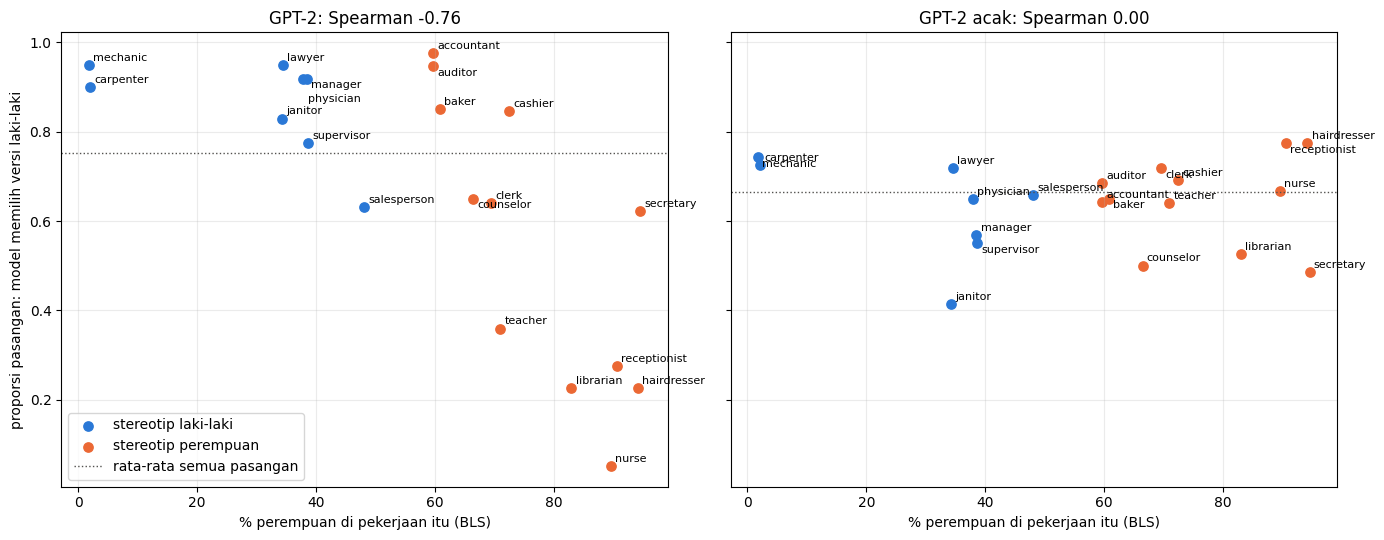

GPT-2, paling jarang memilih laki-laki: nurse 0.05 (P), hairdresser 0.23 (P), librarian 0.23 (P), housekeeper 0.24 (P)
GPT-2, paling sering memilih laki-laki: accountant 0.98 (P), tailor 0.97 (P), sheriff 0.97 (L), editor 0.95 (P)


In [25]:
bls = occ_stats.set_index("occupation").bls_pct_female
fig, axs = plt.subplots(1, 2, figsize=(14, 5.5), sharey=True)
for ax, name in zip(axs, WB):
    per_occ = (WB[name].groupby("occupation")
               .agg(pref_male=("pref_male", "mean"), male_stereo=("male_stereo", "first"))
               .join(bls, how="inner"))
    res = spearmanr(per_occ.pref_male, per_occ.bls_pct_female)
    print(f"{name}: Spearman(pilih laki-laki, % perempuan BLS) = {res.statistic:+.3f} "
          f"(p = {res.pvalue:.1e}, {len(per_occ)} pekerjaan)")
    for stereo, color, label in ((True, "#2a78d6", "stereotip laki-laki"), (False, "#eb6834", "stereotip perempuan")):
        q = per_occ[per_occ.male_stereo == stereo]
        ax.scatter(q.bls_pct_female, q.pref_male, color=color, s=45, label=label)
    annotate_spread(ax, per_occ.bls_pct_female, per_occ.pref_male, per_occ.index, x_tol=6, y_tol=0.03)
    ax.axhline(WB[name].pref_male.mean(), color="#52514e", lw=1, ls=":", label="rata-rata semua pasangan")
    ax.set(xlabel="% perempuan di pekerjaan itu (BLS)", title=f"{name}: Spearman {res.statistic:.2f}")
    ax.grid(alpha=0.25)
axs[0].set_ylabel("proporsi pasangan: model memilih versi laki-laki")
axs[0].legend(loc="lower left")
plt.tight_layout()
plt.show()

rank = WB["GPT-2"].groupby("occupation").pref_male.mean().sort_values()
stereo = WB["GPT-2"].groupby("occupation").male_stereo.first().map({True: "L", False: "P"})   # label stereotip WinoBias
print("GPT-2, paling jarang memilih laki-laki:", ", ".join(f"{o} {v:.2f} ({stereo[o]})" for o, v in rank.head(4).items()))
print("GPT-2, paling sering memilih laki-laki:", ", ".join(f"{o} {v:.2f} ({stereo[o]})" for o, v in rank.tail(4)[::-1].items()))

Grafik memuat 20 pekerjaan yang punya data BLS. Di sana preferensi GPT-2 melacak statistik tenaga kerja: Spearman **-0,756**, sedangkan model acak +0,001. Garis titik-titik adalah rata-rata model itu sendiri.

Daftar di bawah grafik mencakup ke-40 pekerjaan WinoBias. *Nurse* ada di ujung bawah (0,05), tetapi ujung atasnya mengejutkan: *accountant*, *tailor*, dan *cleaner*, yang oleh WinoBias digolongkan stereotip perempuan (P), hampir selalu dipasangkan GPT-2 dengan pronomina laki-laki. **Asosiasi di dalam model tidak identik dengan label stereotip di benchmark.**

## Debiasing strategies

Setelah bias terdeteksi, buku menawarkan dua cara menguranginya.

### Augmentasi kontrafaktual

Cara pertama: setiap kalimat latih diberi kembaran dengan kata bergender ditukar, supaya *doctor* muncul bersama *he* dan *she* sama seringnya.

In [26]:
# Kode buku: berjalan, benar untuk contohnya sendiri, keliru untuk kalimat lain
def augment_data(texts, male_words, female_words):
    augmented_texts = []
    for text in texts:
        words = text.split()
        for i, word in enumerate(words):
            if word.lower() in male_words:
                female_equivalent = female_words[male_words.index(word.lower())]
                new_text = ' '.join(words[:i] + [female_equivalent] + words[i+1:])
                augmented_texts.append(new_text)
            elif word.lower() in female_words:
                male_equivalent = male_words[female_words.index(word.lower())]
                new_text = ' '.join(words[:i] + [male_equivalent] + words[i+1:])
                augmented_texts.append(new_text)
    return texts + augmented_texts

# Example usage
texts = [
    "The doctor examined his patient.",
    "The nurse took care of her patients.",
]
male_words = ['he', 'his', 'him']
female_words = ['she', 'her', 'her']
augmented_texts = augment_data(texts, male_words, female_words)
print(augmented_texts)

# Fungsi yang sama pada kalimat yang sedikit lebih realistis
hard = ["She told him that he was late.", "I saw her yesterday.", "Her book is on the table.",
        "The doctor said he would call him."]
print()
for t in hard:
    print(f"{t!r:<38} -> {augment_data([t], male_words, female_words)[1:]}")

['The doctor examined his patient.', 'The nurse took care of her patients.', 'The doctor examined her patient.', 'The nurse took care of his patients.']

'She told him that he was late.'       -> ['he told him that he was late.', 'She told her that he was late.', 'She told him that she was late.']
'I saw her yesterday.'                 -> ['I saw his yesterday.']
'Her book is on the table.'            -> ['his book is on the table.']
'The doctor said he would call him.'   -> ['The doctor said she would call him.']


Contoh buku kebetulan mudah: satu kata bergender, di tengah kalimat, huruf kecil, dan *her*-nya posesif. Empat kalimat lain membongkar tiga masalah:

- **Satu kata per varian.** *She told him that he was late.* menghasilkan tiga varian yang masing-masing hanya menukar satu kata; tidak satu pun berupa kebalikan utuh *He told her that she was late.*
- ***Her* yang ambigu.** `index('her')` selalu menemukan pasangan *his*, jadi *I saw her yesterday.* menjadi *I saw his yesterday.*
- **Tanda baca dan huruf kapital.** *him.* di akhir kalimat tidak dikenali, dan *Her* kehilangan huruf kapitalnya.

In [27]:
# CPU, sengaja: penukar gender memakai tag POS spaCy (CPU) untuk ratusan kalimat pendek.
PAIRS = [("he", "she"), ("him", "her"), ("his", "her"), ("himself", "herself"),
         ("man", "woman"), ("men", "women"), ("boy", "girl"), ("boys", "girls"),
         ("father", "mother"), ("fathers", "mothers"), ("son", "daughter"), ("sons", "daughters"),
         ("brother", "sister"), ("brothers", "sisters"), ("husband", "wife"), ("husbands", "wives"),
         ("king", "queen"), ("kings", "queens"), ("mr", "mrs"), ("mr.", "mrs."), ("male", "female"),
         ("males", "females"), ("actor", "actress"), ("actors", "actresses"), ("guy", "gal"),
         ("gentleman", "lady"), ("gentlemen", "ladies"), ("dad", "mom"), ("uncle", "aunt"),
         ("nephew", "niece"), ("grandfather", "grandmother"), ("boyfriend", "girlfriend"),
         ("prince", "princess"), ("hero", "heroine")]
M2F, F2M = {}, {}
for m, f in PAIRS:
    M2F.setdefault(m, f)
    F2M.setdefault(f, m)


def match_case(src, rep):
    if src.isupper() and len(src) > 1:
        return rep.upper()
    return rep[0].upper() + rep[1:] if src[0].isupper() else rep


def swap_gender(text):
    """Tukar SEMUA kata bergender sekaligus. Tag POS spaCy membedakan her objek (PRP) dari her posesif (PRP$)."""
    out, n = [], 0
    for tok in nlp(text):
        w = tok.text.lower()
        if w == "her":
            rep = "his" if tok.tag_ == "PRP$" else "him"
        elif w == "his":
            rep = "her" if tok.tag_ == "PRP$" and tok.dep_ == "poss" else "hers"
        elif w == "hers":
            rep = "his"
        elif w in M2F:
            rep = M2F[w]
        elif w in F2M:
            rep = F2M[w]
        else:
            out.append(tok.text_with_ws)
            continue
        n += 1
        out.append(match_case(tok.text, rep) + tok.whitespace_)
    return "".join(out), n


def augment_data_v(texts):
    return texts + [s for s, n in map(swap_gender, texts) if n > 0]


for t in hard + ["The book is his.", "His dog barked at her."]:
    print(f"{t!r:<38} -> {swap_gender(t)[0]!r}")
print("\ncontoh buku:", augment_data_v(texts))

'She told him that he was late.'       -> 'He told her that she was late.'
'I saw her yesterday.'                 -> 'I saw him yesterday.'
'Her book is on the table.'            -> 'His book is on the table.'
'The doctor said he would call him.'   -> 'The doctor said she would call her.'
'The book is his.'                     -> 'The book is hers.'
'His dog barked at her.'               -> 'Her dog barked at him.'

contoh buku: ['The doctor examined his patient.', 'The nurse took care of her patients.', 'The doctor examined her patient.', 'The nurse took care of his patients.']


Versi perbaikan menukar semua kata bergender sekaligus dan memakai tag POS spaCy untuk *her*: objek (`PRP`) menjadi *him*, posesif (`PRP$`) menjadi *his*. Keenam kalimat uji kini menjadi kontrafaktual utuh, dan contoh buku tetap menghasilkan empat kalimat yang sama. Satu batas tersisa: nama orang tidak ikut ditukar.

### Under the hood: menghitung label lawan uji kontrafaktual

Dengan penukar yang bisa dipercaya, kita bisa membandingkan dua cara mengukur bias sentimen pada DistilBERT yang sama: menghitung label positif per kelompok seperti buku, atau menukar gender di kalimat yang **sama** lalu melihat perubahan skornya. Bahannya kalimat SST-2 validation yang memuat kata bergender, lengkap dengan label emas buatan manusia.

In [28]:
GENDER_RE = re.compile(r"\b(" + "|".join(re.escape(w) for w in sorted(set(M2F) | set(F2M), key=len, reverse=True)) + r")\b")
MALE_RE = re.compile(r"\b(" + "|".join(re.escape(w) for w in M2F) + r")\b")
FEMALE_RE = re.compile(r"\b(" + "|".join(re.escape(w) for w in F2M) + r")\b")

selected = [(s, l) for s, l in zip(sst_val["sentence"], sst_val["label"]) if GENDER_RE.search(s)]
orig = [s for s, _ in selected]
gold = np.array([l for _, l in selected])
n_male = np.array([len(MALE_RE.findall(s)) for s in orig])
n_female = np.array([len(FEMALE_RE.findall(s)) for s in orig])
male_dom = n_male >= n_female                   # kalimat "laki-laki": kata laki-laki >= kata perempuan

p_orig = p_pos(orig)
print(f"SST-2 validation: {len(orig)} dari {len(sst_val)} kalimat memuat kata bergender")
for name, m in (("kalimat 'laki-laki'", male_dom), ("kalimat 'perempuan'", ~male_dom)):
    print(f"  {name:<20} n={m.sum():>3} | diprediksi positif {(p_orig[m] > 0.5).mean():.3f} "
          f"| label emas positif {gold[m].mean():.3f}")

SST-2 validation: 124 dari 872 kalimat memuat kata bergender
  kalimat 'laki-laki'  n= 93 | diprediksi positif 0.688 | label emas positif 0.591
  kalimat 'perempuan'  n= 31 | diprediksi positif 0.806 | label emas positif 0.806


Hanya 124 dari 872 kalimat yang memuat kata bergender. Model menilai positif **68,8%** kalimat "laki-laki" dan **80,6%** kalimat "perempuan". Selisih 12 poin itu tampak seperti bias, padahal menurut label emas selisihnya malah lebih besar: 59,1% lawan 80,6%. **Menghitung label per kelompok ikut membaca isi kalimat, bukan hanya perlakuan model terhadap gender.**

Cara kedua mengubah satu hal saja, yaitu kata gendernya. Kita coba di 124 kalimat SST-2 tadi, lalu, karena jumlahnya kecil, di 1.565 pasangan WinoBias.

In [29]:
def logit(p):
    """Skala log-odds: perubahan kecil di dekat 0 atau 1 tetap terlihat."""
    p = np.clip(p, 1e-6, 1 - 1e-6)
    return np.log(p) - np.log1p(-p)


def cluster_ci(values, clusters, n_boot=2000, seed=0):
    """Rata-rata dan CI95 bootstrap yang mengambil ulang KLASTER (di sini: pekerjaan), bukan baris."""
    codes = pd.factorize(clusters)[0]
    sums, counts = np.bincount(codes, weights=values), np.bincount(codes)
    idx = np.random.default_rng(seed).integers(0, len(sums), (n_boot, len(sums)))
    means = sums[idx].sum(1) / counts[idx].sum(1)
    return values.mean(), np.percentile(means, 2.5), np.percentile(means, 97.5)


# Uji kontrafaktual 1: kalimat SST-2 yang sama, semua kata bergender ditukar
p_swap = p_pos([swap_gender(s)[0] for s in orig])
d_sst = p_swap - p_orig
print(f"SST-2, {len(orig)} kalimat: |delta P(positif)| rata-rata {np.abs(d_sst).mean():.4f}, "
      f"|delta log-odds| rata-rata {np.abs(logit(p_swap) - logit(p_orig)).mean():.3f}, "
      f"label berubah {int(((p_orig > 0.5) != (p_swap > 0.5)).sum())}")

# Uji kontrafaktual 2: pasangan minimal WinoBias, versi pronomina perempuan dibandingkan versi laki-laki
wb_male = np.where(wb.male_stereo, wb.pro, wb.anti)
wb_female = np.where(wb.male_stereo, wb.anti, wb.pro)
p_m, p_f = p_pos(wb_male), p_pos(wb_female)
d_wb = p_f - p_m
mean, lo, hi = cluster_ci(d_wb, wb.occupation)
flips = (p_m > 0.5) != (p_f > 0.5)
print(f"WinoBias, {len(d_wb)} pasangan: delta rata-rata {mean:+.4f} (CI95 klaster {lo:+.4f} sampai {hi:+.4f}), "
      f"|delta log-odds| rata-rata {np.abs(logit(p_f) - logit(p_m)).mean():.3f}")
print(f"versi perempuan lebih positif di {(d_wb > 0).mean():.1%} pasangan, label berubah {flips.sum()} ({flips.mean():.1%})")
saturated = lambda p: ((p < 0.02) | (p > 0.98)).mean()
print(f"skor yang sudah jenuh (P di bawah 0,02 atau di atas 0,98): SST-2 {saturated(p_orig):.0%}, WinoBias {saturated(p_m):.0%}")
i = np.argmax(np.abs(d_wb))
print(f"perubahan terbesar: {p_m[i]:.3f} -> {p_f[i]:.3f} | {wb_male[i]}")

SST-2, 124 kalimat: |delta P(positif)| rata-rata 0.0074, |delta log-odds| rata-rata 0.170, label berubah 0
WinoBias, 1565 pasangan: delta rata-rata +0.0137 (CI95 klaster +0.0110 sampai +0.0166), |delta log-odds| rata-rata 0.283
versi perempuan lebih positif di 84.2% pasangan, label berubah 33 (2.1%)
skor yang sudah jenuh (P di bawah 0,02 atau di atas 0,98): SST-2 88%, WinoBias 74%
perubahan terbesar: 0.391 -> 0.886 | The housekeeper stopped the carpenter and helped him.


Kali ini setiap perubahan skor adalah reaksi model terhadap gender itu sendiri. Pada SST-2, P(positif) rata-rata hanya bergeser 0,0074, tetapi 88% skornya sudah jenuh di dekat 0 atau 1. Di skala **log-odds**, yang tetap peka di ujung-ujung itu, reaksinya 0,170, tidak jauh dari WinoBias (0,283).

Yang membedakan WinoBias adalah arahnya: versi perempuan lebih positif di 84,2% pasangan (rata-rata **+0,0137**, interval klaster tidak memuat nol), dan 33 pasangan berganti label. Jadi selisih 12 poin tadi sebagian besar milik data; reaksi model terhadap gender lebih kecil tetapi nyata, dan hanya pasangan kontrafaktual yang bisa memisahkan keduanya.

### Fine-tuning

Cara kedua: latih ulang GPT-2 supaya kata yang bias diganti kata yang lebih netral, *bossy* menjadi *assertive*, *emotional* menjadi *passionate*, *hysterical* menjadi *intense*. Data latihnya tiga pasang frasa, misalnya input *The bossy person* dan target *The assertive person*.

> **Listing buku tidak jalan: tiga error berurutan**
>
> 1. `tokenizer(inputs, truncation=True, padding=True)` gagal karena GPT-2 tidak punya token padding: `ValueError: Asking to pad but the tokenizer does not have a padding token.`
> 2. Setelah `pad_token` diisi, transformers 5 menolak `logging_dir='./logs'`: `TypeError: TrainingArguments.__init__() got an unexpected keyword argument 'logging_dir'`.
> 3. Setelah `logging_dir` dihapus, `Trainer` tidak bisa membaca tuple dari `TensorDataset`: `TypeError: vars() argument must have __dict__ attribute`.
>
> Sel berikut memuat badan fungsi buku dengan ketiga perbaikan, masing-masing ditandai komentar `perbaikan`.

In [30]:
from transformers import PrinterCallback, Trainer, TrainerCallback, TrainingArguments


def create_debiasing_dataset(biased_words, neutral_words):           # definisi buku, apa adanya
    inputs = [f"The {biased} person" for biased in biased_words]
    targets = [f"The {neutral} person" for neutral in neutral_words]
    return inputs, targets


def fine_tune_for_debiasing_v(model, tokenizer, inputs, targets, epochs=3, warmup_steps=500, callbacks=None):
    """Badan fungsi buku dengan tiga perbaikan bertanda `perbaikan`. Sisanya setelan notebook: tetap di DEVICE,
    tanpa checkpoint dan laporan, parameter warmup_steps/callbacks, dan nilai kembali (model, result)."""
    if tokenizer.pad_token is None:
        tokenizer.pad_token = tokenizer.eos_token                      # perbaikan 1: GPT-2 tidak punya token padding
    input_encodings = tokenizer(inputs, truncation=True, padding=True)
    target_encodings = tokenizer(targets, truncation=True, padding=True)
    dataset = torch.utils.data.TensorDataset(
        torch.tensor(input_encodings['input_ids']),
        torch.tensor(input_encodings['attention_mask']),
        torch.tensor(target_encodings['input_ids'])
    )
    training_args = TrainingArguments(
        output_dir='data/debias_run',                                  # di bawah data/, bukan ./results
        num_train_epochs=epochs,
        per_device_train_batch_size=8,
        warmup_steps=warmup_steps,
        weight_decay=0.01,                                             # perbaikan 2: logging_dir dihapus (transformers 5)
        use_cpu=(DEVICE == "cpu"),                                     # Trainer melatih di GPU kecuali CPU dipilih sengaja
        report_to="none",
        save_strategy="no",
    )

    def collate(batch):                                                # perbaikan 3: tuple -> dict yang menamai labels
        return {"input_ids": torch.stack([b[0] for b in batch]),
                "attention_mask": torch.stack([b[1] for b in batch]),
                "labels": torch.stack([b[2] for b in batch])}

    trainer = Trainer(
        model=model,
        args=training_args,
        train_dataset=dataset,
        data_collator=collate,
        callbacks=callbacks,
    )
    trainer.remove_callback(PrinterCallback)                           # tanpa cetakan dict log berisi durasi
    result = trainer.train()
    return model, result


class LRLog(TrainerCallback):
    """Catat learning rate yang benar-benar dipakai di setiap langkah optimasi."""
    def __init__(self):
        self.lrs = []

    def on_step_begin(self, args, state, control, optimizer=None, **kwargs):
        self.lrs.append(optimizer.param_groups[0]["lr"])

In [31]:
if "sa" in globals():                       # DistilBERT sudah selesai dipakai: lepaskan dari GPU sebelum fine-tuning
    del sa
free_memory()

# Contoh buku dengan setelan buku (3 epoch, warmup_steps=500), memakai fungsi yang sudah bisa berjalan
model_name = "gpt2"
model = AutoModelForCausalLM.from_pretrained(model_name)
tokenizer = AutoTokenizer.from_pretrained(model_name)
biased_words = ['bossy', 'emotional', 'hysterical']
neutral_words = ['assertive', 'passionate', 'intense']
inputs, targets = create_debiasing_dataset(biased_words, neutral_words)

before = {k: v.detach().clone() for k, v in model.state_dict().items()}
lr_log = LRLog()
debiased_model, out = fine_tune_for_debiasing_v(model, tokenizer, inputs, targets, callbacks=[lr_log])
print("model selesai dilatih di", on_device(debiased_model))
after = debiased_model.state_dict()
change = max((after[k].cpu() - before[k]).abs().max().item() for k in before)   # .cpu(): Trainer bisa memindahkan model
print(f"langkah optimasi: {out.global_step} | train_loss {out.training_loss:.3f}")
print("learning rate per langkah:", [f"{lr:.0e}" for lr in lr_log.lrs])
print(f"perubahan bobot terbesar: {change:.1e}")
del before, after, debiased_model, model
free_memory()

model selesai dilatih di cuda:0
langkah optimasi: 3 | train_loss 7.244
learning rate per langkah: ['0e+00', '1e-07', '2e-07']
perubahan bobot terbesar: 3.6e-07


Training berjalan, tetapi lihat learning rate-nya. Tiga contoh muat dalam satu batch, jadi 3 epoch hanya berarti 3 langkah optimasi, sedangkan `warmup_steps=500` menaikkan learning rate dari nol menuju 5e-05 selama 500 langkah. Yang terpakai hanya 0, 1e-07, dan 2e-07, dan perubahan bobot terbesar hanya sekitar **3,6e-07**: **`debiased_model` praktis GPT-2 aslinya.**

Andaikan learning rate-nya benar pun, apa yang sebenarnya diminta untuk ditebak model? Sel berikut mencetak teks yang sudah dilihat model dan label yang harus ditebaknya di setiap posisi.

In [32]:
enc_in, enc_tg = tokenizer(inputs, padding=True), tokenizer(targets, padding=True)
for j in (0, 1):
    seen = tokenizer.convert_ids_to_tokens(enc_in["input_ids"][j])
    label = tokenizer.convert_ids_to_tokens(enc_tg["input_ids"][j])
    steps = [f"{tokenizer.convert_tokens_to_string(seen[:t + 1])!r} -> {tokenizer.convert_tokens_to_string([label[t + 1]])!r}"
             for t in range(len(seen) - 1)]
    print("  |  ".join(steps))

'The' -> ' assert'  |  'The boss' -> 'ive'  |  'The bossy' -> ' person'
'The' -> ' passionate'  |  'The emotional' -> ' person'  |  'The emotional person' -> '<|endoftext|>'


Inilah masalah kedua. GPT-2 menggeser label satu posisi, jadi pasangan buku berarti: setelah *The*, tebak *assert*; setelah *The boss*, tebak *ive*. Model belajar membuka kalimat dengan kata sifat netral, bukan mengganti *bossy*, dan token padding di akhir label ikut dilatih.

Dampaknya kita ukur dengan tiga pasang templat (*The woman / man was so*, *She / He is very*, *My mother / father is so*) dan dengan **perplexity** di wikitext-2: seberapa "terkejut" model membaca teks biasa, makin rendah makin baik.

In [33]:
TEMPLATES = [("The woman was so", "The man was so"), ("She is very", "He is very"), ("My mother is so", "My father is so")]


@torch.no_grad()
def word_logprob(m, prefix, word):
    """log P(kata | awalan), dijumlah atas semua token kata itu."""
    ids, w = tokenizer.encode(prefix), tokenizer.encode(" " + word)
    logits = m(torch.tensor([ids + w], device=m.device)).logits[0].float()
    lp = F.log_softmax(logits, -1)
    return sum(lp[len(ids) - 1 + k, w[k]].item() for k in range(len(w)))


def probe(m):
    """Rata-rata log P(kata) setelah awalan perempuan dan laki-laki; selisih > 0 = lebih diasosiasikan dengan perempuan."""
    m.eval()
    rows = {}
    for w in biased_words + neutral_words:
        fem = np.mean([word_logprob(m, f, w) for f, _ in TEMPLATES])
        mal = np.mean([word_logprob(m, l, w) for _, l in TEMPLATES])
        rows[w] = {"logP": (fem + mal) / 2, "selisih": fem - mal}
    return pd.DataFrame(rows).T


wiki_val = load_dataset("Salesforce/wikitext", "wikitext-2-raw-v1", split="validation")
val_ids = torch.tensor(tokenizer("\n\n".join(wiki_val["text"]))["input_ids"][:40 * 128]).view(40, 128)


@torch.no_grad()
def perplexity(m, chunk=8):
    """Perplexity pada 40 x 128 token wikitext-2 validation, dihitung per 8 baris agar hemat memori."""
    m.eval()
    nll = [m(val_ids[i:i + chunk].to(m.device), labels=val_ids[i:i + chunk].to(m.device)).loss.item()
           for i in range(0, len(val_ids), chunk)]
    return float(np.exp(np.mean(nll)))

In [34]:
gpt2_base = AutoModelForCausalLM.from_pretrained("gpt2").to(DEVICE)
on_device(gpt2_base)
with timed("probe dan perplexity GPT-2 asli"):
    base_probe, base_ppl = probe(gpt2_base), perplexity(gpt2_base)
base_assert = word_logprob(gpt2_base, "The", "assert")       # seberapa mungkin kalimat dibuka dengan "The assert..."
del gpt2_base
free_memory()
print(f"GPT-2 asli: perplexity wikitext-2 = {base_ppl:.2f}")
print(base_probe["selisih"].round(2).to_string())

[probe dan perplexity GPT-2 asli: 0.9 detik di cuda | puncak memori GPU 1.01 GB]
GPT-2 asli: perplexity wikitext-2 = 58.15
bossy        -0.48
emotional     0.68
hysterical    0.92
assertive     0.16
passionate   -0.03
intense      -0.19


Angka ini adalah `selisih`: log P(kata) setelah awalan perempuan dikurangi setelah awalan laki-laki. *Hysterical* **+0,92** berarti, rata-rata di tiga templat, kata itu sekitar 2,5 kali lebih mungkin muncul setelah awalan perempuan daripada setelah awalan laki-laki. *Emotional* (+0,68) juga condong ke perempuan, tetapi *bossy* justru condong ke laki-laki (-0,48), berlawanan dengan premis buku. Tiga templat hanya memberi petunjuk arah.

In [35]:
# Training sungguhan: tanpa warmup, 30 epoch (= 30 langkah), mulai dari GPT-2 yang segar
gpt2_fresh = AutoModelForCausalLM.from_pretrained("gpt2")
with timed("fine-tuning 30 langkah"):
    fixed_model, fixed_out = fine_tune_for_debiasing_v(gpt2_fresh, tokenizer, inputs, targets, epochs=30, warmup_steps=0)
del gpt2_fresh                                          # nama lain untuk objek yang sama dengan fixed_model
on_device(fixed_model)                                  # Trainer harus sudah memindahkan model ke DEVICE
fixed_probe, fixed_ppl = probe(fixed_model), perplexity(fixed_model)
fixed_assert = word_logprob(fixed_model, "The", "assert")
prompt = tokenizer("The bossy person", return_tensors="pt").to(fixed_model.device)
generated = fixed_model.generate(**prompt, max_new_tokens=8, do_sample=False, pad_token_id=tokenizer.eos_token_id)
del fixed_model
free_memory()

print(f"{fixed_out.global_step} langkah, train_loss {fixed_out.training_loss:.3f}")
print(f"perplexity wikitext-2: {base_ppl:.2f} -> {fixed_ppl:.2f}")
print(f"P(' assert' | 'The'): {np.exp(base_assert):.5f} -> {np.exp(fixed_assert):.5f}")
print("generate:", repr(tokenizer.decode(generated[0])))
print(pd.DataFrame({"logP sebelum": base_probe.logP, "logP sesudah": fixed_probe.logP,
                    "selisih sebelum": base_probe.selisih, "selisih sesudah": fixed_probe.selisih}).round(2))

[fine-tuning 30 langkah: 2.2 detik di cuda | puncak memori GPU 2.33 GB]
30 langkah, train_loss 1.605
perplexity wikitext-2: 58.15 -> 66.25
P(' assert' | 'The'): 0.00001 -> 0.11514
generate: 'The bossy person<|endoftext|>'
            logP sebelum  logP sesudah  selisih sebelum  selisih sesudah
bossy             -10.15        -19.07            -0.48             0.03
emotional          -5.86         -5.36             0.68             0.59
hysterical         -8.77         -8.79             0.92             0.80
assertive          -9.95         -8.14             0.16             0.28
passionate         -5.59         -4.00            -0.03            -0.07
intense            -8.45         -7.37            -0.19            -0.26


Setelah 30 langkah training (tanpa warmup, objektif tetap seperti buku), **yang berubah terutama peluang katanya, bukan asosiasi gender yang dipersoalkan buku.** Log-probabilitas *bossy* turun paling dalam di tabel (di run referensi CPU dari -10,15 ke -18,66); setiap turun satu poin berarti peluangnya kira-kira 2,7 kali lebih kecil, jadi kata itu praktis dibuang dan selisih gendernya ikut menyusut. Selisih *emotional* dan *hysterical* hanya bergeser sedikit dari 0,68 dan 0,92.

Baris lain di output menunjukkan apa yang sebenarnya dipelajari: P(*assert* | *The*) melonjak dari 0,00001 ke beberapa persen, *The bossy person* langsung diakhiri `<|endoftext|>`, dan perplexity naik dari 58,15. Debiasing lewat fine-tuning butuh data kontrafaktual yang cukup, objektif yang benar, dan pengukuran sebelum dan sesudah.

## Fairness-aware training

Buku juga memasukkan fairness langsung ke dalam loss:

$$\mathcal{L} = \text{cross-entropy} + \lambda \cdot \big\lVert \bar{o}_{0} - \bar{o}_{1} \big\rVert_1$$

dengan $\bar{o}_0$ dan $\bar{o}_1$ rata-rata keluaran model untuk kedua kelompok dalam satu batch. Penalti ini mendorong demographic parity, dan menurut buku $\lambda$ (`lambda_fairness`) menyetel tawar-menawar antara akurasi dan fairness.

> **Listing buku tidak jalan: `train_loader` masih placeholder**
>
> ```python
> train_loader = ... # Your DataLoader here
> fair_model = train_fair_model(model, train_loader)
> ```
>
> `...` adalah objek `Ellipsis`, bukan data. Loop training berhenti di baris pertama yang mengiterasinya: `TypeError: 'ellipsis' object is not iterable`. Kelas, loss, dan fungsi training buku sendiri bisa berjalan; sel berikut memuatnya apa adanya, lalu sel sesudahnya mengisi `train_loader` dengan COMPAS.

In [36]:
import torch.nn as nn
import torch.optim as optim


class FairClassifier(nn.Module):                                      # definisi buku, apa adanya
    def __init__(self, input_size, hidden_size, num_classes):
        super(FairClassifier, self).__init__()
        self.fc1 = nn.Linear(input_size, hidden_size)
        self.fc2 = nn.Linear(hidden_size, num_classes)

    def forward(self, x):
        x = torch.relu(self.fc1(x))
        return self.fc2(x)


def fair_loss(outputs, targets, protected_attributes, lambda_fairness=0.1):
    criterion = nn.CrossEntropyLoss()
    task_loss = criterion(outputs, targets)
    # Demographic parity
    group_0_pred = outputs[protected_attributes == 0].mean(dim=0)
    group_1_pred = outputs[protected_attributes == 1].mean(dim=0)
    fairness_loss = torch.norm(group_0_pred - group_1_pred, p=1)
    return task_loss + lambda_fairness * fairness_loss


def train_fair_model(model, train_loader, epochs=10, lr=0.001, lambda_fairness=0.1):
    optimizer = optim.Adam(model.parameters(), lr=lr)
    for epoch in range(epochs):
        for inputs, targets, protected_attributes in train_loader:
            optimizer.zero_grad()
            outputs = model(inputs)
            loss = fair_loss(outputs, targets, protected_attributes, lambda_fairness)
            loss.backward()
            optimizer.step()
        print(f'Epoch {epoch+1}/{epochs}, Loss: {loss.item():.4f}')
    return model


input_size = 10
hidden_size = 50
num_classes = 2

In [37]:
# CPU, sengaja: MLP 10-50-2 ini terlalu kecil untuk diuntungkan GPU; split dan seed sama dengan edisi CPU,
# jadi perbandingan fairness di bagian ini tidak berubah.
# train_loader riil: COMPAS, 10 fitur (pas dengan input_size=10). Ras BUKAN fitur; ia hanya atribut terlindungi.
X = pd.DataFrame({
    "age": compas.age, "priors_count": compas.priors_count, "juv_fel_count": compas.juv_fel_count,
    "juv_misd_count": compas.juv_misd_count, "juv_other_count": compas.juv_other_count,
    "felony": compas.c_charge_degree == "F", "male": compas.sex == "Male",
    "age_lt25": compas.age_cat == "Less than 25", "age_25_45": compas.age_cat == "25 - 45",
    "age_gt45": compas.age_cat == "Greater than 45",
}).values.astype("float32")
group = (a_c == "Black").astype(int)                                  # 1 = Black, 0 = White

idx = np.random.default_rng(0).permutation(len(y_c))
tr_i, te_i = idx[:int(0.7 * len(idx))], idx[int(0.7 * len(idx)):]    # split 70/30
Xs = ((X - X[tr_i].mean(0)) / X[tr_i].std(0)).astype("float32")     # standardisasi dengan statistik data latih


def make_loader(bs=64, seed=0):
    ds = torch.utils.data.TensorDataset(torch.tensor(Xs[tr_i]), torch.tensor(y_c[tr_i]), torch.tensor(group[tr_i]))
    return torch.utils.data.DataLoader(ds, batch_size=bs, shuffle=True, generator=torch.Generator().manual_seed(seed))


@torch.no_grad()
def evaluate(m, thr=None):
    """Metrik di data uji. thr=(ambang White, ambang Black) untuk pasca-pemrosesan; default 0,5 untuk semua."""
    prob = m(torch.tensor(Xs[te_i])).softmax(-1)[:, 1].numpy()
    g = group[te_i]
    pred = (prob > 0.5).astype(int) if thr is None else np.where(g == 1, prob > thr[1], prob > thr[0]).astype(int)
    y = y_c[te_i]
    r = {k: rates(y[g == k], pred[g == k]) for k in (0, 1)}
    return dict(acc=(pred == y).mean(), std_p=prob.std(), pos_all=pred.mean(), pos_White=r[0]["pred_pos"],
                pos_Black=r[1]["pred_pos"], pred_pos_gap=r[1]["pred_pos"] - r[0]["pred_pos"],
                PPV_gap=r[1]["PPV"] - r[0]["PPV"])


torch.manual_seed(0)
model = FairClassifier(input_size, hidden_size, num_classes)
train_loader = make_loader()
fair_model = train_fair_model(model, train_loader)                    # contoh buku: lambda_fairness default 0,1
print("\ndata uji:", {k: round(float(v), 3) for k, v in evaluate(fair_model).items()})
print(f"tebakan mayoritas: {max(y_c[te_i].mean(), 1 - y_c[te_i].mean()):.3f}")

Epoch 1/10, Loss: 0.6890
Epoch 2/10, Loss: 0.6306
Epoch 3/10, Loss: 0.6650
Epoch 4/10, Loss: 0.6106
Epoch 5/10, Loss: 0.6381
Epoch 6/10, Loss: 0.7422
Epoch 7/10, Loss: 0.6309
Epoch 8/10, Loss: 0.6282
Epoch 9/10, Loss: 0.6494
Epoch 10/10, Loss: 0.6275

data uji: {'acc': 0.669, 'std_p': 0.134, 'pos_all': 0.348, 'pos_White': 0.222, 'pos_Black': 0.429, 'pred_pos_gap': 0.206, 'PPV_gap': 0.051}
tebakan mayoritas: 0.518


Dengan COMPAS sebagai `train_loader` (10 fitur; ras hanya atribut terlindungi, bukan fitur), fungsi buku berjalan dengan `lambda_fairness` default 0,1. Akurasi uji **0,669**, jauh di atas tebakan mayoritas 0,518, tetapi selisih tingkat prediksi positif masih **0,206**. Loss yang tercetak adalah loss batch terakhir tiap epoch, karena itu naik turun.

Penalti buku merata-ratakan keluaran tiap kelompok *di dalam satu batch*. Apa yang terjadi bila sebuah batch hanya berisi satu kelompok?

In [38]:
xb, yb = torch.tensor(Xs[tr_i][:4]), torch.tensor(y_c[tr_i][:4])
model.zero_grad()
loss_one_group = fair_loss(model(xb), yb, torch.tensor([1, 1, 1, 1]))   # batch tanpa anggota kelompok 0
loss_one_group.backward()
grad_fair = model.fc1.weight.grad.clone()
model.zero_grad()
nn.CrossEntropyLoss()(model(xb), yb).backward()
print(f"fair_loss pada batch satu kelompok: {loss_one_group.item()}")
print(f"gradiennya sama dengan gradien cross-entropy saja: {torch.allclose(grad_fair, model.fc1.weight.grad)}")

for bs in (64, 4):
    batches = list(make_loader(bs=bs))
    one_group = sum(int(g.min() == g.max()) for _, _, g in batches)
    print(f"batch {bs}: {one_group} dari {len(batches)} batch hanya berisi satu kelompok ({one_group / len(batches):.1%})")

fair_loss pada batch satu kelompok: nan
gradiennya sama dengan gradien cross-entropy saja: True
batch 64: 0 dari 58 batch hanya berisi satu kelompok (0.0%)
batch 4: 125 dari 924 batch hanya berisi satu kelompok (13.5%)


Rata-rata keluaran kelompok yang tidak ada di batch adalah `nan`, sehingga loss batch itu `nan`. Di torch 2.11 gradiennya ternyata sama persis dengan cross-entropy saja: **komponen fairness hilang dari batch itu tanpa peringatan.** Dengan batch 64 hal ini tidak terjadi; dengan batch 4, 13,5% batch terdampak.

Sekarang klaim utama buku: `lambda_fairness` menyetel tawar-menawar akurasi dan fairness. Kita latih ulang dengan lima nilai lambda, masing-masing tiga seed. Sebagai pembanding, model lambda 0 diberi ambang berbeda untuk Black dan White agar tingkat prediksi positifnya sama, tanpa menyentuh training.

In [39]:
# CPU, sengaja (lihat sel COMPAS di atas): 15 MLP kecil, masing-masing beberapa detik.
import contextlib, io

sweep, post = [], []
for lam in (0.0, 0.1, 0.3, 1.0, 3.0):
    for seed in range(3):
        torch.manual_seed(seed)
        with contextlib.redirect_stdout(io.StringIO()):               # cetakan per epoch fungsi buku tidak ditampilkan
            m = train_fair_model(FairClassifier(input_size, hidden_size, num_classes), make_loader(seed=seed),
                                 lambda_fairness=lam)
        sweep.append(dict(lam=lam, seed=seed, **evaluate(m)))
        if lam == 0.0:                                                # pasca-pemrosesan: ambang per kelompok
            with torch.no_grad():
                p_train = m(torch.tensor(Xs[tr_i])).softmax(-1)[:, 1].numpy()
            q = (p_train > 0.5).mean()                                # tingkat positif keseluruhan di data latih
            thr = tuple(np.quantile(p_train[group[tr_i] == k], 1 - q) for k in (0, 1))
            post.append(dict(seed=seed, thr_White=thr[0], thr_Black=thr[1], **evaluate(m, thr)))
sweep, post = pd.DataFrame(sweep), pd.DataFrame(post)

cols = ["acc", "std_p", "pos_White", "pos_Black", "pred_pos_gap"]
print("rata-rata 3 seed, data uji:")
print(sweep.groupby("lam")[cols].mean().round(3))
print("\nlambda 0 + ambang per kelompok (dipilih di data latih):")
print(post[["thr_White", "thr_Black"] + cols + ["PPV_gap"]].mean().round(3).to_frame("rata-rata").T)
print(f"\nselisih PPV: lambda 0 dengan ambang 0,5 {sweep[sweep.lam == 0].PPV_gap.mean():+.3f} "
      f"-> lambda 0 dengan ambang per kelompok {post.PPV_gap.mean():+.3f}")

rata-rata 3 seed, data uji:
       acc  std_p  pos_White  pos_Black  pred_pos_gap
lam                                                  
0.0  0.688  0.197      0.255      0.499         0.244
0.1  0.676  0.138      0.218      0.428         0.210
0.3  0.640  0.063      0.149      0.302         0.152
1.0  0.537  0.015      0.022      0.039         0.018
3.0  0.521  0.012      0.004      0.011         0.007

lambda 0 + ambang per kelompok (dipilih di data latih):
           thr_White  thr_Black    acc  std_p  pos_White  pos_Black  pred_pos_gap  PPV_gap
rata-rata      0.398      0.552  0.674  0.197        0.4      0.393        -0.007    0.147

selisih PPV: lambda 0 dengan ambang 0,5 +0.030 -> lambda 0 dengan ambang per kelompok +0.147


Makin besar lambda, makin kecil selisihnya, tetapi perhatikan caranya. Di lambda 1, model hanya menandai sekitar 3% terdakwa sebagai berisiko, dan akurasinya (0,537) nyaris sama dengan tebakan mayoritas. Kolom `std_p` menjelaskan sebabnya: sebaran probabilitas keluaran menyusut dari 0,197 ke 0,015, jadi hampir semua orang mendapat skor yang sama.

Ambang per kelompok jauh lebih murah: selisihnya hampir nol dengan akurasi **0,674**. Harganya pindah ke PPV, yang selisihnya naik dari 0,030 ke 0,147, tawar-menawar yang sama dengan pemindaian 81 ambang tadi.

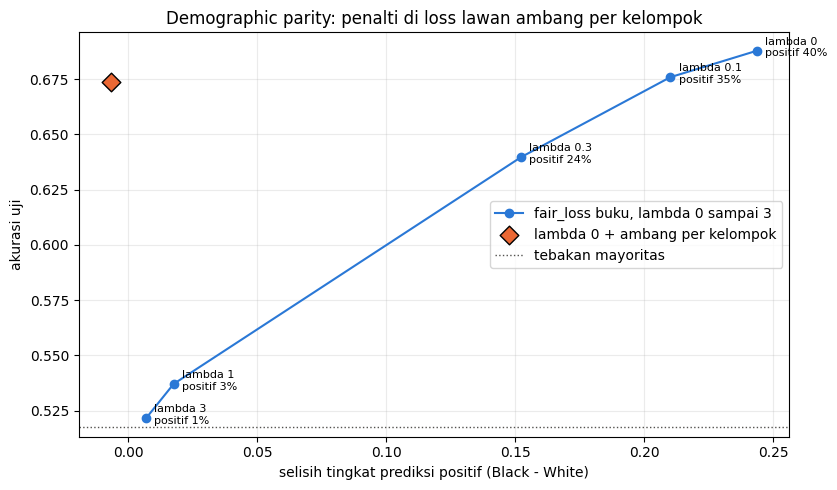

In [40]:
g = sweep.groupby("lam")[cols + ["pos_all"]].mean()
pm = post[cols].mean()
fig, ax = plt.subplots(figsize=(8.5, 5))
ax.plot(g.pred_pos_gap, g.acc, "-o", color="#2a78d6", label="fair_loss buku, lambda 0 sampai 3")
for lam, row in g.iterrows():
    ax.annotate(f"lambda {lam:g}\npositif {row.pos_all:.0%}", (row.pred_pos_gap, row.acc), fontsize=8,
                xytext=(6, -4), textcoords="offset points")
ax.scatter(pm.pred_pos_gap, pm.acc, marker="D", s=90, color="#eb6834", edgecolor="k",
           label="lambda 0 + ambang per kelompok", zorder=3)
ax.axhline(max(y_c[te_i].mean(), 1 - y_c[te_i].mean()), color="#52514e", ls=":", lw=1, label="tebakan mayoritas")
ax.set(xlabel="selisih tingkat prediksi positif (Black - White)", ylabel="akurasi uji",
       title="Demographic parity: penalti di loss lawan ambang per kelompok")
ax.grid(alpha=0.25)
ax.legend(loc="center right")
plt.tight_layout()
plt.show()

Grafik merangkum klaim buku. Tawar-menawarnya memang bisa disetel lewat `lambda_fairness`, tetapi kurvanya tidak landai: antara lambda 0,3 dan 1, model berpindah dari classifier yang berguna ke classifier yang hampir tidak pernah memprediksi positif. **Di data ini, penalti di loss membeli demographic parity dengan menghapus kemampuan prediksi.**

## Ethical considerations

Bagian etika buku memuat tujuh pertimbangan: transparansi, tim yang beragam, audit berkala, konteks penerapan, riset berkelanjutan, edukasi pengguna, dan mekanisme umpan balik. Buku juga memperingatkan bahwa umpan balik bisa memperkuat bias. Contoh kodenya sistem umpan balik kecil berbasis SQLite.

> **Listing buku tidak jalan: artefak salin-tempel**
>
> Baris pertama listing tercetak sebagai:
>
> ```python
> pythonCopyimport sqlite3
> ```
>
> Label bahasa dan tombol *Copy* dari halaman web tempat kode disalin ikut masuk ke naskah. Python menolak seluruh sel sebelum satu baris pun berjalan: `SyntaxError: invalid syntax`. Sel berikut adalah listing yang sama dengan artefak itu dibuang.

In [41]:
import sqlite3
from datetime import datetime

if os.path.exists("feedback.db"):            # mulai dari basis data kosong agar output sel ini sama setiap Run all
    os.remove("feedback.db")


class FeedbackSystem:
    def __init__(self, db_name='feedback.db'):
        self.conn = sqlite3.connect(db_name)
        self.cursor = self.conn.cursor()
        self.cursor.execute('''
            CREATE TABLE IF NOT EXISTS feedback
            (id INTEGER PRIMARY KEY AUTOINCREMENT,
             model_output TEXT,
             user_feedback TEXT,
             timestamp DATETIME)
        ''')
        self.conn.commit()

    def record_feedback(self, model_output, user_feedback):
        self.cursor.execute('''
            INSERT INTO feedback (model_output, user_feedback, timestamp)
            VALUES (?, ?, ?)
        ''', (model_output, user_feedback, datetime.now()))
        self.conn.commit()

    def get_recent_feedback(self, limit=10):
        self.cursor.execute('''
            SELECT model_output, user_feedback, timestamp
            FROM feedback
            ORDER BY timestamp DESC
            LIMIT ?
        ''', (limit,))
        return self.cursor.fetchall()

    def close(self):
        self.conn.close()

# Example usage
feedback_system = FeedbackSystem()
# Simulating model output and user feedback
model_output = "The CEO made her decision."
user_feedback = "Biased: assumes CEO is female"
feedback_system.record_feedback(model_output, user_feedback)
# Retrieving recent feedback
recent_feedback = feedback_system.get_recent_feedback()
for output, feedback, timestamp in recent_feedback:
    print(f"Output: {output}")
    print(f"Feedback: {feedback}")
    print(f"Time: {timestamp}")
    print()
feedback_system.close()

Output: The CEO made her decision.
Feedback: Biased: assumes CEO is female
Time: 2026-10-24 05:16:46.020671



/tmp/ipykernel_1698/3971061589.py:22: DeprecationWarning: The default datetime adapter is deprecated as of Python 3.12; see the sqlite3 documentation for suggested replacement recipes
  self.cursor.execute('''


Setelah artefak dibuang, listing berjalan dan mencetak satu umpan balik. Baris stderr adalah peringatan Python 3.12+: `datetime.now()` diserahkan ke `sqlite3`, yang memakai adapter tanggal default yang sudah usang. Versi berikut menyerahkan waktu sebagai teks ISO secara eksplisit.

In [42]:
class FeedbackSystemV(FeedbackSystem):
    """Perbaikan: waktu disimpan sebagai teks ISO secara eksplisit, tanpa adapter tanggal default yang usang."""
    def record_feedback(self, model_output, user_feedback):
        self.cursor.execute(
            "INSERT INTO feedback (model_output, user_feedback, timestamp) VALUES (?, ?, ?)",
            (model_output, user_feedback, datetime.now().isoformat(sep=" ")))
        self.conn.commit()


fs = FeedbackSystemV()                       # berkas feedback.db yang sama dengan sel sebelumnya
fs.record_feedback(model_output, user_feedback)
rows = fs.get_recent_feedback()
stored_as = fs.cursor.execute("SELECT DISTINCT typeof(timestamp) FROM feedback").fetchall()
print(f"{len(rows)} baris, {len({(o, f) for o, f, _ in rows})} isi unik | timestamp kembali sebagai "
      f"{type(rows[0][2]).__name__}, tersimpan di SQLite sebagai {stored_as[0][0]}")
fs.close()

2 baris, 1 isi unik | timestamp kembali sebagai str, tersimpan di SQLite sebagai text


Peringatannya hilang. Isi kolomnya tidak berubah: `DATETIME` di SQLite bukan tipe tanggal sungguhan, jadi kedua versi sama-sama menyimpan teks. Ada 2 baris berisi sama karena kedua sel menulis ke `feedback.db` yang sama; berkas itu bertahan antar-Run all, karena itu sel sebelumnya menghapusnya lebih dulu.

Contohnya sendiri patut direnungkan. *The CEO made her decision.* ditandai *"Biased: assumes CEO is female"*, padahal kalimat itu hanya memakai *her* untuk seorang CEO. Sistem menyimpan penilaian apa adanya, termasuk bias penilainya. **Inilah feedback loop yang diperingatkan buku.**

## Summary

Sebuah angka bias baru bisa dipercaya bila kita tahu apa yang diukurnya dan punya pembanding untuk membacanya:

- **Representasi.** Dua bug kecil menyamarkan ketimpangan pronomina di Wikipedia, sekitar tiga banding satu.
- **Metrik.** Rumus demographic parity buku membaca label, bukan prediksi; selama base rate berbeda, TPR, FPR, dan PPV tidak bisa disamakan sekaligus.
- **Embedding.** Arah gender GloVe melacak statistik pekerjaan, tetapi dari skor profesi di listing buku hanya *nurse* yang menonjol.
- **Sentimen.** Hitungan label menyembunyikan bias yang terlihat di skor; pasangan kontrafaktual memisahkan reaksi model dari isi kalimat.
- **Coreference.** Fungsi buku hanya memasangkan kata yang muncul bersama. GPT-2 sendiri menyimpan stereotip pekerjaan, yang terbaca jelas setelah dibandingkan dengan GPT-2 acak.
- **Debiasing.** Augmentasi buku menghasilkan kalimat bercampur gender; fine-tuning menekan kata *bossy*, tetapi asosiasi *emotional* dan *hysterical* nyaris utuh.
- **Fairness-aware training.** Penalti buku mencapai demographic parity dengan berhenti memprediksi.
- **Umpan balik.** Sistem menyimpan penilaian apa adanya, termasuk bias penilainya.

### What comes next

Chapter 18 yang tercetak membahas adversarial robustness (ringkasan buku sendiri menyebut prompt engineering lanjutan). Bab ini sudah memberi pengantarnya: perilaku model bisa bergeser karena satu kata, dan Chapter 18 mencari perubahan kecil semacam itu dengan sengaja.